Set up paths and inspect official dataset directories

In [66]:
from google.colab import drive
drive.mount("/content/drive")

import os
import subprocess

REPO_URL = "https://github.com/Sakina152/mm-dg-healthcare.git"
REPO_DIR = "/content/mm-dg-healthcare"

if not os.path.isdir(os.path.join(REPO_DIR, ".git")):
    subprocess.run(
        ["git", "clone", REPO_URL, REPO_DIR],
        check=True
    )

os.chdir(REPO_DIR)
print("Working directory:", os.getcwd())
!git log -1 --oneline


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working directory: /content/mm-dg-healthcare
7c0583f (HEAD -> main, origin/main, origin/HEAD) Update 08


In [6]:

from pathlib import Path
import requests
from html.parser import HTMLParser
from urllib.parse import urljoin
import pandas as pd

REPO = Path("/content/mm-dg-healthcare")
PTB_DIR = REPO / "data/raw/ptbxl"
OUT = REPO / "experiments/results/lead_observability_pilot"
OUT.mkdir(parents=True, exist_ok=True)

assert PTB_DIR.joinpath("ptbxl_database.csv").exists()
assert PTB_DIR.joinpath("scp_statements.csv").exists()

BASE = "https://physionet.org/files/challenge-2021/1.0.3/training/"

DATASETS = {
    "chapman_shaoxing": BASE + "chapman_shaoxing/g1/",
    "cpsc_2018": BASE + "cpsc_2018/g1/",
    "georgia": BASE + "georgia/g1/",
}

class DirectoryParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.hrefs = []

    def handle_starttag(self, tag, attrs):
        if tag.lower() == "a":
            for key, value in attrs:
                if key.lower() == "href" and value:
                    self.hrefs.append(value)

def inspect_directory(url):
    response = requests.get(url, timeout=60)
    response.raise_for_status()

    parser = DirectoryParser()
    parser.feed(response.text)

    files = sorted({
        href.rsplit("/", 1)[-1]
        for href in parser.hrefs
        if href.lower().endswith((".hea", ".mat", ".dat"))
    })

    return files

for dataset, url in DATASETS.items():
    try:
        files = inspect_directory(url)
        print(f"\n{dataset}: {url}")
        print("Files found:", len(files))
        print("Examples:", files[:8])
    except Exception as exc:
        print(f"\n{dataset}: directory inspection failed")
        print(repr(exc))



chapman_shaoxing: https://physionet.org/files/challenge-2021/1.0.3/training/chapman_shaoxing/g1/
Files found: 1998
Examples: ['JS00001.hea', 'JS00001.mat', 'JS00002.hea', 'JS00002.mat', 'JS00004.hea', 'JS00004.mat', 'JS00005.hea', 'JS00005.mat']

cpsc_2018: https://physionet.org/files/challenge-2021/1.0.3/training/cpsc_2018/g1/
Files found: 1998
Examples: ['A0001.hea', 'A0001.mat', 'A0002.hea', 'A0002.mat', 'A0003.hea', 'A0003.mat', 'A0004.hea', 'A0004.mat']

georgia: https://physionet.org/files/challenge-2021/1.0.3/training/georgia/g1/
Files found: 1998
Examples: ['E00001.hea', 'E00001.mat', 'E00002.hea', 'E00002.mat', 'E00003.hea', 'E00003.mat', 'E00004.hea', 'E00004.mat']


In [3]:

from pathlib import Path
import tarfile
import pandas as pd

REPO = Path("/content/mm-dg-healthcare")
ARCHIVE = Path("/content/drive/MyDrive/mm-dg-healthcare-data/ptbxl.tar")
RAW = REPO / "data" / "raw"

assert REPO.exists(), f"Repository missing: {REPO}"
assert ARCHIVE.exists(), f"Drive archive missing: {ARCHIVE}"

RAW.mkdir(parents=True, exist_ok=True)

with tarfile.open(ARCHIVE, "r:*") as tar:
    # Prevent archive paths from escaping the destination directory.
    for member in tar.getmembers():
        target = (RAW / member.name).resolve()
        if not target.is_relative_to(RAW.resolve()):
            raise ValueError(f"Unsafe archive path: {member.name}")

    tar.extractall(RAW, filter="data")

PTB_DIR = RAW / "ptbxl"
db_path = PTB_DIR / "ptbxl_database.csv"
scp_path = PTB_DIR / "scp_statements.csv"

assert db_path.exists(), f"Metadata not found: {db_path}"
assert scp_path.exists(), f"SCP mapping not found: {scp_path}"

df = pd.read_csv(db_path)
scp = pd.read_csv(scp_path, index_col=0)

print("PTB-XL restored successfully.")
print("PTB-XL directory:", PTB_DIR)
print("Records:", len(df))
print("SCP statements:", len(scp))
print("Database shape:", df.shape)


PTB-XL restored successfully.
PTB-XL directory: /content/mm-dg-healthcare/data/raw/ptbxl
Records: 21799
SCP statements: 71
Database shape: (21799, 28)


Inspect the official diagnosis labels and signal headers

In [7]:

from pathlib import Path
import requests

HEADER_DIR = OUT / "sample_headers"
HEADER_DIR.mkdir(parents=True, exist_ok=True)

for dataset, url in DATASETS.items():
    try:
        files = inspect_directory(url)
        headers = [name for name in files if name.lower().endswith(".hea")]

        if not headers:
            print(f"{dataset}: no headers listed")
            continue

        name = headers[0]
        response = requests.get(urljoin(url, name), timeout=60)
        response.raise_for_status()

        path = HEADER_DIR / f"{dataset}_{name}"
        path.write_bytes(response.content)

        print(f"\n--- {dataset} / {name} ---")
        print(response.text[:2500])

    except Exception as exc:
        print(f"{dataset}: failed: {exc}")



--- chapman_shaoxing / JS00001.hea ---
JS00001 12 500 5000
JS00001.mat 16x1+24 1000.0(0)/mV 16 0 -254 21756 0 I
JS00001.mat 16x1+24 1000.0(0)/mV 16 0 264 -599 0 II
JS00001.mat 16x1+24 1000.0(0)/mV 16 0 517 -22376 0 III
JS00001.mat 16x1+24 1000.0(0)/mV 16 0 -5 28232 0 aVR
JS00001.mat 16x1+24 1000.0(0)/mV 16 0 -386 16619 0 aVL
JS00001.mat 16x1+24 1000.0(0)/mV 16 0 390 15121 0 aVF
JS00001.mat 16x1+24 1000.0(0)/mV 16 0 -98 1568 0 V1
JS00001.mat 16x1+24 1000.0(0)/mV 16 0 -312 -32761 0 V2
JS00001.mat 16x1+24 1000.0(0)/mV 16 0 -98 32715 0 V3
JS00001.mat 16x1+24 1000.0(0)/mV 16 0 810 15193 0 V4
JS00001.mat 16x1+24 1000.0(0)/mV 16 0 810 14081 0 V5
JS00001.mat 16x1+24 1000.0(0)/mV 16 0 527 32579 0 V6
# Age: 85
# Sex: Male
# Dx: 164889003,59118001,164934002
# Rx: Unknown
# Hx: Unknown
# Sx: Unknown


--- cpsc_2018 / A0001.hea ---
A0001 12 500 7500
A0001.mat 16x1+24 1000.0(0)/mV 16 0 28 -1716 0 I
A0001.mat 16x1+24 1000.0(0)/mV 16 0 7 2029 0 II
A0001.mat 16x1+24 1000.0(0)/mV 16 0 -21 3745 0 III
A0

Save the audit report to Google Drive

In [8]:

from pathlib import Path
import shutil
from google.colab import drive

drive.mount("/content/drive")

BACKUP = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)
BACKUP.mkdir(parents=True, exist_ok=True)

# Back up sample headers
if HEADER_DIR.exists():
    shutil.copytree(
        HEADER_DIR,
        BACKUP / "sample_headers",
        dirs_exist_ok=True
    )

print("Pilot audit files backed up to:", BACKUP)
for p in sorted(BACKUP.rglob("*")):
    if p.is_file():
        print(p.relative_to(BACKUP), f"({p.stat().st_size:,} bytes)")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Pilot audit files backed up to: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/lead_observability_pilot
sample_headers/chapman_shaoxing_JS00001.hea (760 bytes)
sample_headers/cpsc_2018_A0001.hea (700 bytes)
sample_headers/georgia_E00001.hea (713 bytes)


Audit the dataset metadata systematically

In [9]:

from pathlib import Path
from urllib.parse import urljoin
from html.parser import HTMLParser
import requests
import pandas as pd
import re

class LinkParser(HTMLParser):
    def __init__(self):
        super().__init__()
        self.links = []

    def handle_starttag(self, tag, attrs):
        if tag.lower() == "a":
            for key, value in attrs:
                if key.lower() == "href" and value:
                    self.links.append(value)

def list_links(url):
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    parser = LinkParser()
    parser.feed(response.text)
    return sorted(set(parser.links))

def parse_header_text(text, dataset, filename):
    lines = text.splitlines()
    first = lines[0].split() if lines else []

    if len(first) < 4:
        return None

    try:
        n_leads = int(first[1])
        fs = float(first[2])
        n_samples = int(first[3])
    except (ValueError, IndexError):
        return None

    lead_names = []
    for line in lines[1:]:
        parts = line.split()
        if len(parts) >= 2:
            lead_names.append(parts[-1])

    def comment_value(key):
        pattern = rf"^\s*#{key}\s*:\s*(.*)$"
        for line in lines:
            match = re.match(pattern, line, flags=re.IGNORECASE)
            if match:
                return match.group(1).strip()
        return None

    duration = n_samples / fs if fs > 0 else None

    return {
        "dataset": dataset,
        "header": filename,
        "n_leads": n_leads,
        "sampling_hz": fs,
        "n_samples": n_samples,
        "duration_seconds": duration,
        "lead_names": ";".join(lead_names),
        "diagnosis_codes": comment_value("Dx"),
        "age": comment_value("Age"),
        "sex": comment_value("Sex"),
    }

AUDIT_DIR = OUT / "metadata_audit"
AUDIT_DIR.mkdir(parents=True, exist_ok=True)

rows = []

for dataset, url in DATASETS.items():
    print(f"Auditing {dataset} ...")

    links = list_links(url)
    headers = sorted(
        link.rsplit("/", 1)[-1]
        for link in links
        if link.lower().endswith(".hea")
    )

    print("Header files listed:", len(headers))

    # Sample up to 50 headers for a quick metadata audit.
    # This is a pilot, not a full-dataset inventory.
    for filename in headers[:50]:
        try:
            response = requests.get(urljoin(url, filename), timeout=60)
            response.raise_for_status()

            row = parse_header_text(
                response.text, dataset, filename
            )
            if row is not None:
                rows.append(row)

        except Exception as exc:
            print("Header failed:", filename, repr(exc))

audit_df = pd.DataFrame(rows)

csv_path = AUDIT_DIR / "external_metadata_sample_audit.csv"
audit_df.to_csv(csv_path, index=False)

print("\nSaved:", csv_path)
display(audit_df.groupby("dataset").agg(
    sampled_records=("header", "count"),
    lead_counts=("n_leads", lambda s: sorted(s.unique().tolist())),
    sampling_rates=("sampling_hz", lambda s: sorted(s.unique().tolist())),
    durations=("duration_seconds", lambda s: sorted(s.unique().tolist())),
))


Auditing chapman_shaoxing ...
Header files listed: 999
Auditing cpsc_2018 ...
Header files listed: 999
Auditing georgia ...
Header files listed: 999

Saved: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/metadata_audit/external_metadata_sample_audit.csv


,sampled_records,lead_counts,sampling_rates,durations
dataset,,,,
chapman_shaoxing,50,[12],[500.0],[10.0]
cpsc_2018,50,[12],[500.0],"[10.0, 10.554, 10.568, 10.994, 11.0, 11.614, 1..."
georgia,50,[12],[500.0],[10.0]


Inspect the available dataset groups and diagnosis mapping files

In [10]:

from urllib.parse import urljoin
import pandas as pd

print("Dataset group directories and mapping files")

for dataset, url in DATASETS.items():
    parent_url = url.rsplit("g1/", 1)[0]
    try:
        links = list_links(parent_url)
        names = sorted(link.rstrip("/").split("/")[-1] for link in links)

        groups = [
            name for name in names
            if name.startswith("g") and name[1:].isdigit()
        ]

        mapping_files = [
            name for name in names
            if any(key in name.lower() for key in [
                "mapping", "diagnos", "snomed", "label", "reference"
            ])
        ]

        print(f"\n{dataset}")
        print("Group folders:", groups)
        print("Potential mapping/reference files:", mapping_files[:30])

    except Exception as exc:
        print(dataset, "directory inspection failed:", repr(exc))


Dataset group directories and mapping files

chapman_shaoxing
Group folders: ['g1', 'g10', 'g11', 'g2', 'g3', 'g4', 'g5', 'g6', 'g7', 'g8', 'g9']
Potential mapping/reference files: []

cpsc_2018
Group folders: ['g1', 'g2', 'g3', 'g4', 'g5', 'g6', 'g7']
Potential mapping/reference files: []

georgia
Group folders: ['g1', 'g10', 'g11', 'g2', 'g3', 'g4', 'g5', 'g6', 'g7', 'g8', 'g9']
Potential mapping/reference files: []


In [11]:

import requests
from bs4 import BeautifulSoup
import pandas as pd

BASE = "https://physionet.org/files/challenge-2021/1.0.3/training/"

DATASETS = [
    "chapman_shaoxing",
    "cpsc_2018",
    "georgia",
]

session = requests.Session()
rows = []

for dataset in DATASETS:
    parent_url = BASE + dataset + "/"
    response = session.get(parent_url, timeout=60)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    groups = sorted(
        {
            link.get("href", "").strip("/")
            for link in soup.find_all("a")
            if link.get("href", "").strip("/").startswith("g")
            and link.get("href", "").strip("/")[1:].isdigit()
        },
        key=lambda name: int(name[1:])
    )

    print(f"\n{dataset}: {len(groups)} groups")

    total_headers = 0

    for group in groups:
        url = f"{parent_url}{group}/"
        r = session.get(url, timeout=60)
        r.raise_for_status()

        group_soup = BeautifulSoup(r.text, "html.parser")
        count = sum(
            1 for a in group_soup.find_all("a")
            if a.get("href", "").lower().endswith(".hea")
        )

        total_headers += count
        rows.append({
            "dataset": dataset,
            "group": group,
            "header_count": count,
        })

        print(f"  {group}: {count} headers")

    print("Total headers:", total_headers)

group_audit = pd.DataFrame(rows)
display(group_audit)

out = (
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot/group_coverage_audit.csv"
)
group_audit.to_csv(out, index=False)
print("Saved:", out)



chapman_shaoxing: 11 groups
  g1: 999 headers
  g2: 1000 headers
  g3: 1000 headers
  g4: 1000 headers
  g5: 1000 headers
  g6: 1000 headers
  g7: 1000 headers
  g8: 1000 headers
  g9: 1000 headers
  g10: 1000 headers
  g11: 248 headers
Total headers: 10247

cpsc_2018: 7 groups
  g1: 999 headers
  g2: 1000 headers
  g3: 1000 headers
  g4: 1000 headers
  g5: 1000 headers
  g6: 1000 headers
  g7: 878 headers
Total headers: 6877

georgia: 11 groups
  g1: 999 headers
  g2: 1000 headers
  g3: 1000 headers
  g4: 1000 headers
  g5: 1000 headers
  g6: 1000 headers
  g7: 1000 headers
  g8: 1000 headers
  g9: 1000 headers
  g10: 1000 headers
  g11: 345 headers
Total headers: 10344


,dataset,group,header_count
0,chapman_shaoxing,g1,999
1,chapman_shaoxing,g2,1000
2,chapman_shaoxing,g3,1000
3,chapman_shaoxing,g4,1000
4,chapman_shaoxing,g5,1000
5,chapman_shaoxing,g6,1000
6,chapman_shaoxing,g7,1000
7,chapman_shaoxing,g8,1000
8,chapman_shaoxing,g9,1000
9,chapman_shaoxing,g10,1000


Saved: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/group_coverage_audit.csv


In [12]:

from pathlib import Path
import requests
import pandas as pd

mapping_dir = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot/label_mapping"
)
mapping_dir.mkdir(parents=True, exist_ok=True)

base = (
    "https://raw.githubusercontent.com/"
    "physionetchallenges/evaluation-2021/master/"
)

for filename in [
    "dx_mapping_scored.csv",
    "dx_mapping_unscored.csv",
]:
    response = requests.get(base + filename, timeout=60)
    response.raise_for_status()

    path = mapping_dir / filename
    path.write_bytes(response.content)

    df = pd.read_csv(path)
    print(f"\n{filename}: {df.shape}")
    print("Columns:", df.columns.tolist())
    display(df.head())

print("\nMapping files saved to:", mapping_dir)



dx_mapping_scored.csv: (30, 13)
Columns: ['Dx', 'SNOMEDCTCode', 'Abbreviation', 'CPSC', 'CPSC_Extra', 'StPetersburg', 'PTB', 'PTB_XL', 'Georgia', 'Chapman_Shaoxing', 'Ningbo', 'Total', 'Notes']


,Dx,SNOMEDCTCode,Abbreviation,CPSC,CPSC_Extra,StPetersburg,PTB,PTB_XL,Georgia,Chapman_Shaoxing,Ningbo,Total,Notes
0,atrial fibrillation,164889003,AF,1221,153,2,15,1514,570,1780,0,5255,NaN
1,atrial flutter,164890007,AFL,0,54,0,1,73,186,445,7615,8374,NaN
2,bundle branch block,6374002,BBB,0,0,1,20,0,116,0,385,522,NaN
3,bradycardia,426627000,Brady,0,271,11,0,0,6,0,7,295,NaN
4,complete left bundle branch block,733534002,CLBBB,0,0,0,0,0,0,0,213,213,We score 733534002 and 164909002 as the same d...



dx_mapping_unscored.csv: (103, 12)
Columns: ['Dx', 'SNOMEDCTCode', 'Abbreviation', 'CPSC', 'CPSC_Extra', 'StPetersburg', 'PTB', 'PTB_XL', 'Georgia', 'Chapman_Shaoxing', 'Ningbo', 'Total']


,Dx,SNOMEDCTCode,Abbreviation,CPSC,CPSC_Extra,StPetersburg,PTB,PTB_XL,Georgia,Chapman_Shaoxing,Ningbo,Total
0,accelerated atrial escape rhythm,233892002,AAR,0,0,0,0,0,0,0,16,16
1,abnormal QRS,164951009,abQRS,0,0,0,0,3389,0,0,0,3389
2,atrial escape beat,251187003,AED,0,0,0,0,0,0,0,17,17
3,accelerated idioventricular rhythm,61277005,AIVR,0,0,0,0,0,0,0,14,14
4,accelerated junctional rhythm,426664006,AJR,0,0,0,0,0,19,0,12,31



Mapping files saved to: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/label_mapping


Identify the best shared diagnosis labels

In [13]:

from pathlib import Path
import pandas as pd

RESULTS = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
MAPPING_DIR = RESULTS / "label_mapping"

scored = pd.read_csv(MAPPING_DIR / "dx_mapping_scored.csv")

columns = [
    "Dx",
    "SNOMEDCTCode",
    "Abbreviation",
    "PTB_XL",
    "Georgia",
    "Chapman_Shaoxing",
    "CPSC",
]

counts = scored[columns].copy()

count_cols = ["PTB_XL", "Georgia", "Chapman_Shaoxing", "CPSC"]
for col in count_cols:
    counts[col] = pd.to_numeric(counts[col], errors="coerce").fillna(0)

# These are mapping-table counts, not yet verified counts from our loaded files.
counts["minimum_shared_count"] = counts[count_cols].min(axis=1)
counts["total_across_four"] = counts[count_cols].sum(axis=1)

# Require at least 100 mapped examples in every source for this initial shortlist.
shortlist = counts[
    (counts[count_cols] >= 100).all(axis=1)
].sort_values("minimum_shared_count", ascending=False)

print("Scored classes:", len(counts))
print("Classes with >=100 mapped records in all four sources:", len(shortlist))
display(shortlist)

out = RESULTS / "shared_scored_label_shortlist.csv"
shortlist.to_csv(out, index=False)
print("Saved:", out)


Scored classes: 30
Classes with >=100 mapped records in all four sources: 5


,Dx,SNOMEDCTCode,Abbreviation,PTB_XL,Georgia,Chapman_Shaoxing,CPSC,minimum_shared_count,total_across_four
13,sinus rhythm,426783006,NSR,18092,1752,1826,918,918,22588
0,atrial fibrillation,164889003,AF,1514,570,1780,1221,570,5085
14,premature atrial contraction,284470004,PAC,398,639,258,616,258,1911
6,1st degree av block,270492004,IAVB,797,769,247,722,247,2535
10,left bundle branch block,164909002,LBBB,536,231,205,236,205,1208


Saved: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/shared_scored_label_shortlist.csv


In [14]:

from pathlib import Path
from google.colab import drive
import shutil

drive.mount("/content/drive")

source_dir = Path(
    "/content/mm-dg-healthcare/experiments/results/lead_observability_pilot"
)

backup_dir = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)
backup_dir.mkdir(parents=True, exist_ok=True)

files_to_backup = [
    source_dir / "shared_scored_label_shortlist.csv",
    source_dir / "group_coverage_audit.csv",
]

for src in files_to_backup:
    if not src.exists():
        print("MISSING:", src.name)
        continue

    dst = backup_dir / src.name
    shutil.copy2(src, dst)

    if src.stat().st_size == dst.stat().st_size:
        print(f"Verified: {dst.name} ({dst.stat().st_size:,} bytes)")
    else:
        print(f"SIZE MISMATCH: {dst.name}")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Verified: shared_scored_label_shortlist.csv (416 bytes)
Verified: group_coverage_audit.csv (602 bytes)


audit diagnosis codes in real headers

In [15]:

from pathlib import Path
from collections import Counter
import requests
import pandas as pd
from bs4 import BeautifulSoup

BASE = "https://physionet.org/files/challenge-2021/1.0.3/training/"
RESULTS = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
MAPPING_DIR = RESULTS / "label_mapping"

mapping = pd.read_csv(MAPPING_DIR / "dx_mapping_scored.csv")
mapping["SNOMEDCTCode"] = (
    mapping["SNOMEDCTCode"].astype(str).str.replace(r"\.0$", "", regex=True)
)

TARGET_CODES = {
    "426783006": "NSR",
    "164889003": "AF",
    "284470004": "PAC",
    "270492004": "IAVB",
    "164909002": "LBBB",
}

DATASETS = {
    "chapman_shaoxing": "Chapman_Shaoxing",
    "cpsc_2018": "CPSC",
    "georgia": "Georgia",
}

session = requests.Session()
header_rows = []
code_counts = Counter()
errors = []

for dataset, mapping_column in DATASETS.items():
    parent_url = f"{BASE}{dataset}/"
    r = session.get(parent_url, timeout=60)
    r.raise_for_status()
    soup = BeautifulSoup(r.text, "html.parser")

    groups = sorted(
        {
            a.get("href", "").strip("/")
            for a in soup.find_all("a")
            if a.get("href", "").strip("/").startswith("g")
            and a.get("href", "").strip("/")[1:].isdigit()
        },
        key=lambda x: int(x[1:])
    )

    for group in groups:
        group_url = f"{parent_url}{group}/"
        r = session.get(group_url, timeout=60)
        r.raise_for_status()
        group_soup = BeautifulSoup(r.text, "html.parser")

        headers = sorted({
            a.get("href")
            for a in group_soup.find_all("a")
            if a.get("href", "").lower().endswith(".hea")
        })[:25]

        for filename in headers:
            try:
                hr = session.get(group_url + filename, timeout=30)
                hr.raise_for_status()
                lines = hr.text.splitlines()

                dx_line = next(
                    (line for line in lines
                     if line.strip().lower().startswith("#dx")),
                    ""
                )
                dx_codes = []
                if ":" in dx_line:
                    dx_codes = [
                        code.strip()
                        for code in dx_line.split(":", 1)[1].split(",")
                        if code.strip()
                    ]

                for code in set(dx_codes):
                    code_counts[(dataset, code)] += 1

                header_rows.append({
                    "dataset": dataset,
                    "group": group,
                    "record": filename[:-4],
                    "dx_codes": ";".join(dx_codes),
                    "target_labels": ";".join(
                        TARGET_CODES[c] for c in dx_codes
                        if c in TARGET_CODES
                    ),
                    "header_download_ok": True,
                })

            except Exception as e:
                errors.append({
                    "dataset": dataset,
                    "group": group,
                    "record": filename,
                    "error": str(e),
                })

audit = pd.DataFrame(header_rows)
audit.to_csv(RESULTS / "sampled_header_label_audit.csv", index=False)

summary_rows = []
for dataset in DATASETS:
    sampled = audit[audit["dataset"] == dataset]
    for code, label in TARGET_CODES.items():
        summary_rows.append({
            "dataset": dataset,
            "label": label,
            "SNOMEDCTCode": code,
            "sampled_headers": len(sampled),
            "records_with_label": sum(
                code in codes.split(";")
                for codes in sampled["dx_codes"]
            ),
        })

summary = pd.DataFrame(summary_rows)
display(summary.pivot(
    index="label", columns="dataset", values="records_with_label"
))
print("Successfully fetched headers:", len(audit))
print("Failed header requests:", len(errors))
print("Detailed audit saved to:", RESULTS / "sampled_header_label_audit.csv")

if errors:
    display(pd.DataFrame(errors).head(10))


dataset,chapman_shaoxing,cpsc_2018,georgia
label,,,
AF,0,0,0
IAVB,0,0,0
LBBB,0,0,0
NSR,0,0,0
PAC,0,0,0


Successfully fetched headers: 725
Failed header requests: 0
Detailed audit saved to: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/sampled_header_label_audit.csv


In [16]:

from pathlib import Path
import requests
import pandas as pd
from bs4 import BeautifulSoup
from google.colab import drive
import shutil

BASE = "https://physionet.org/files/challenge-2021/1.0.3/training/"
RESULTS = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
RESULTS.mkdir(parents=True, exist_ok=True)

datasets = ["chapman_shaoxing", "cpsc_2018", "georgia"]
session = requests.Session()
inspection = []

for dataset in datasets:
    group_url = f"{BASE}{dataset}/g1/"
    response = session.get(group_url, timeout=60)
    response.raise_for_status()

    soup = BeautifulSoup(response.text, "html.parser")
    headers = sorted(
        a.get("href") for a in soup.find_all("a")
        if a.get("href", "").lower().endswith(".hea")
    )[:3]

    print(f"\n{'=' * 60}\n{dataset}")

    for filename in headers:
        response = session.get(group_url + filename, timeout=30)
        response.raise_for_status()
        lines = response.text.splitlines()

        # Print every comment line, especially diagnosis annotations.
        comment_lines = [
            line for line in lines
            if line.lstrip().startswith("#")
        ]

        print(f"\n{filename}")
        for line in comment_lines:
            print(repr(line))

        inspection.append({
            "dataset": dataset,
            "record": filename,
            "comment_lines": " || ".join(comment_lines),
        })

inspection_df = pd.DataFrame(inspection)
out = RESULTS / "diagnosis_line_format_inspection.csv"
inspection_df.to_csv(out, index=False)
print("\nInspection saved:", out)

# Back up both the inspection and the previous audit to Google Drive.
drive.mount("/content/drive")

backup = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)
backup.mkdir(parents=True, exist_ok=True)

files_to_copy = [
    out,
    RESULTS / "sampled_header_label_audit.csv",
]

for src in files_to_copy:
    if not src.exists():
        print("MISSING:", src.name)
        continue

    dst = backup / src.name
    shutil.copy2(src, dst)

    if dst.exists() and dst.stat().st_size == src.stat().st_size:
        print(f"VERIFIED Drive backup: {dst.name} ({dst.stat().st_size:,} bytes)")
    else:
        print(f"BACKUP VERIFICATION FAILED: {dst.name}")



chapman_shaoxing

JS00001.hea
'# Age: 85'
'# Sex: Male'
'# Dx: 164889003,59118001,164934002'
'# Rx: Unknown'
'# Hx: Unknown'
'# Sx: Unknown'

JS00002.hea
'# Age: 59'
'# Sex: Female'
'# Dx: 426177001,164934002'
'# Rx: Unknown'
'# Hx: Unknown'
'# Sx: Unknown'

JS00004.hea
'# Age: 66'
'# Sex: Male'
'# Dx: 426177001'
'# Rx: Unknown'
'# Hx: Unknown'
'# Sx: Unknown'

cpsc_2018

A0001.hea
'# Age: 74'
'# Sex: Male'
'# Dx: 59118001'
'# Rx: Unknown'
'# Hx: Unknown'
'# Sx: Unknown'

A0002.hea
'# Age: 49'
'# Sex: Female'
'# Dx: 426783006'
'# Rx: Unknown'
'# Hx: Unknown'
'# Sx: Unknown'

A0003.hea
'# Age: 81'
'# Sex: Female'
'# Dx: 164889003'
'# Rx: Unknown'
'# Hx: Unknown'
'# Sx: Unknown'

georgia

E00001.hea
'# Age: NaN'
'# Sex: Female'
'# Dx: 426783006'
'# Rx: Unknown'
'# Hx: Unknown'

E00002.hea
'# Age: NaN'
'# Sex: Female'
'# Dx: 426783006'
'# Rx: Unknown'
'# Hx: Unknown'

E00003.hea
'# Age: NaN'
'# Sex: Male'
'# Dx: 426783006'
'# Rx: Unknown'
'# Hx: Unknown'

Inspection saved: /content/mm-dg

In [17]:

from pathlib import Path
from collections import Counter
import re
import requests
import pandas as pd
from google.colab import drive
import shutil

BASE = "https://physionet.org/files/challenge-2021/1.0.3/training/"
RESULTS = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
RESULTS.mkdir(parents=True, exist_ok=True)

# Reuse the exact sample from the earlier audit.
previous = pd.read_csv(RESULTS / "sampled_header_label_audit.csv")

TARGET_CODES = {
    "164889003": "AF",
    "270492004": "IAVB",
    "164909002": "LBBB",
    "426783006": "NSR",
    "284470004": "PAC",
}

session = requests.Session()
rows = []
errors = []

for _, old in previous.iterrows():
    dataset = old["dataset"]
    group = old["group"]
    record = old["record"]

    url = f"{BASE}{dataset}/{group}/{record}.hea"

    try:
        response = session.get(url, timeout=30)
        response.raise_for_status()

        lines = response.text.splitlines()

        # Correctly matches '# Dx:', including the space after '#'.
        dx_line = next(
            (
                line for line in lines
                if re.match(r"^\s*#\s*Dx\s*:", line, flags=re.I)
            ),
            None,
        )

        codes = []
        if dx_line:
            value = re.split(r":", dx_line, maxsplit=1)[1]
            codes = [
                code.strip()
                for code in value.split(",")
                if code.strip()
            ]

        matched = [TARGET_CODES[c] for c in codes if c in TARGET_CODES]

        rows.append({
            "dataset": dataset,
            "group": group,
            "record": record,
            "dx_line": dx_line or "",
            "dx_codes": ";".join(codes),
            "target_labels": ";".join(matched),
            "header_download_ok": True,
        })

    except Exception as e:
        errors.append({
            "dataset": dataset,
            "group": group,
            "record": record,
            "error": str(e),
        })

audit = pd.DataFrame(rows)

detail_path = RESULTS / "sampled_header_label_audit_corrected.csv"
audit.to_csv(detail_path, index=False)

summary_rows = []
for dataset in sorted(previous["dataset"].unique()):
    subset = audit[audit["dataset"] == dataset]

    for code, label in TARGET_CODES.items():
        count = sum(
            code in row.split(";")
            for row in subset["dx_codes"]
        )
        summary_rows.append({
            "dataset": dataset,
            "label": label,
            "SNOMEDCTCode": code,
            "sampled_records": len(subset),
            "records_with_label": count,
        })

summary = pd.DataFrame(summary_rows)
summary_path = RESULTS / "sampled_header_label_summary_corrected.csv"
summary.to_csv(summary_path, index=False)

print("Corrected sample counts:")
display(summary.pivot(
    index="label",
    columns="dataset",
    values="records_with_label"
))
print("Successfully audited:", len(audit))
print("Failed requests:", len(errors))

if errors:
    display(pd.DataFrame(errors).head(10))

# Back up the corrected outputs to Google Drive.
drive.mount("/content/drive")

backup = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)
backup.mkdir(parents=True, exist_ok=True)

for src in [detail_path, summary_path]:
    dst = backup / src.name
    shutil.copy2(src, dst)

    if dst.exists() and dst.stat().st_size == src.stat().st_size:
        print(f"VERIFIED Drive backup: {dst.name} ({dst.stat().st_size:,} bytes)")
    else:
        print(f"BACKUP VERIFICATION FAILED: {dst.name}")


Corrected sample counts:


dataset,chapman_shaoxing,cpsc_2018,georgia
label,,,
AF,52,32,15
IAVB,11,25,25
LBBB,5,8,8
NSR,52,23,58
PAC,6,8,21


Successfully audited: 725
Failed requests: 0
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERIFIED Drive backup: sampled_header_label_audit_corrected.csv (52,573 bytes)
VERIFIED Drive backup: sampled_header_label_summary_corrected.csv (550 bytes)


full external label audit

In [18]:

from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed
from threading import Lock
import requests, re, time, shutil
import pandas as pd
from bs4 import BeautifulSoup
from google.colab import drive

BASE = "https://physionet.org/files/challenge-2021/1.0.3/training/"
OUT = Path("/content/mm-dg-healthcare/experiments/results/lead_observability_pilot")
OUT.mkdir(parents=True, exist_ok=True)

BACKUP = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)

DATASETS = ["chapman_shaoxing", "cpsc_2018", "georgia"]
TARGET_CODES = {
    "164889003": "AF",
    "270492004": "IAVB",
    "164909002": "LBBB",
    "426783006": "NSR",
    "284470004": "PAC",
}

session_local = __import__("threading").local()
print_lock = Lock()

def get_session():
    if not hasattr(session_local, "session"):
        session_local.session = requests.Session()
    return session_local.session

def get_headers_for_dataset(dataset):
    parent = BASE + dataset + "/"
    r = requests.get(parent, timeout=30)
    r.raise_for_status()
    soup = BeautifulSoup(r.text, "html.parser")
    groups = sorted(
        {a.get("href", "").strip("/")
         for a in soup.find_all("a")
         if re.fullmatch(r"g\d+/?", a.get("href", ""))},
        key=lambda x: int(x[1:])
    )

    urls = []
    for group in groups:
        url = f"{parent}{group}/"
        r = requests.get(url, timeout=30)
        r.raise_for_status()
        group_soup = BeautifulSoup(r.text, "html.parser")
        names = sorted({
            a.get("href") for a in group_soup.find_all("a")
            if a.get("href", "").lower().endswith(".hea")
        })
        urls.extend((dataset, group, url + name, name[:-4]) for name in names)
    return urls

# Build the URL inventory first.
inventory = []
for dataset in DATASETS:
    urls = get_headers_for_dataset(dataset)
    inventory.extend(urls)
    print(dataset, "header files listed:", len(urls))

pd.DataFrame(
    inventory, columns=["dataset", "group", "url", "record"]
).to_csv(OUT / "full_header_inventory.csv", index=False)

def audit_header(item):
    dataset, group, url, record = item
    try:
        r = get_session().get(url, timeout=25)
        r.raise_for_status()
        dx_line = next(
            (line for line in r.text.splitlines()
             if re.match(r"^\s*#\s*Dx\s*:", line, flags=re.I)),
            ""
        )
        codes = []
        if ":" in dx_line:
            codes = [
                x.strip() for x in dx_line.split(":", 1)[1].split(",")
                if x.strip()
            ]
        labels = [TARGET_CODES[c] for c in codes if c in TARGET_CODES]
        return {
            "dataset": dataset, "group": group, "record": record,
            "dx_codes": ";".join(codes),
            "target_labels": ";".join(labels),
            "ok": True, "error": ""
        }
    except Exception as e:
        return {
            "dataset": dataset, "group": group, "record": record,
            "dx_codes": "", "target_labels": "",
            "ok": False, "error": str(e)
        }

detail_path = OUT / "full_header_label_audit.csv"
inventory_df = pd.DataFrame(
    inventory, columns=["dataset", "group", "url", "record"]
)

# Resume from an earlier completed or partially completed audit if present.
if detail_path.exists():
    existing = pd.read_csv(detail_path)
    done = set(zip(existing["dataset"], existing["group"], existing["record"]))
    results = existing.to_dict("records")
    todo = [
        item for item in inventory
        if (item[0], item[1], item[3]) not in done
    ]
    print("Resuming:", len(done), "already processed;", len(todo), "remaining")
else:
    results, todo = [], inventory

start = time.time()
completed = 0
batch_size = 500

with ThreadPoolExecutor(max_workers=12) as pool:
    futures = {pool.submit(audit_header, item): item for item in todo}

    for future in as_completed(futures):
        results.append(future.result())
        completed += 1

        if completed % batch_size == 0:
            pd.DataFrame(results).to_csv(detail_path, index=False)
            print(f"Processed {completed:,}/{len(todo):,} remaining headers")

# Final save
detail = pd.DataFrame(results)
detail.to_csv(detail_path, index=False)

ok = detail[detail["ok"] == True].copy()
summary_rows = []
for dataset in DATASETS:
    subset = ok[ok["dataset"] == dataset]
    for code, label in TARGET_CODES.items():
        count = sum(code in codes.split(";") for codes in subset["dx_codes"])
        summary_rows.append({
            "dataset": dataset,
            "label": label,
            "SNOMEDCTCode": code,
            "successfully_read_headers": len(subset),
            "records_with_label": count,
        })

summary = pd.DataFrame(summary_rows)
summary_path = OUT / "full_header_label_summary.csv"
summary.to_csv(summary_path, index=False)

print("\nFULL AUDIT SUMMARY")
display(summary.pivot(
    index="label", columns="dataset", values="records_with_label"
))
print("Inventory:", len(inventory))
print("Successfully read:", len(ok))
print("Failed:", len(detail) - len(ok))
print("Elapsed minutes:", round((time.time() - start) / 60, 1))

# Back up outputs to Drive and verify file sizes.
drive.mount("/content/drive")
BACKUP.mkdir(parents=True, exist_ok=True)

for src in [
    OUT / "full_header_inventory.csv",
    detail_path,
    summary_path,
]:
    if src.exists():
        dst = BACKUP / src.name
        shutil.copy2(src, dst)
        print(
            "VERIFIED Drive backup:" if dst.exists()
            and dst.stat().st_size == src.stat().st_size
            else "BACKUP VERIFICATION FAILED:",
            dst.name,
            f"({dst.stat().st_size:,} bytes)" if dst.exists() else ""
        )


chapman_shaoxing header files listed: 10247
cpsc_2018 header files listed: 6877
georgia header files listed: 10344
Processed 500/27,468 remaining headers
Processed 1,000/27,468 remaining headers
Processed 1,500/27,468 remaining headers
Processed 2,000/27,468 remaining headers
Processed 2,500/27,468 remaining headers
Processed 3,000/27,468 remaining headers
Processed 3,500/27,468 remaining headers
Processed 4,000/27,468 remaining headers
Processed 4,500/27,468 remaining headers
Processed 5,000/27,468 remaining headers
Processed 5,500/27,468 remaining headers
Processed 6,000/27,468 remaining headers
Processed 6,500/27,468 remaining headers
Processed 7,000/27,468 remaining headers
Processed 7,500/27,468 remaining headers
Processed 8,000/27,468 remaining headers
Processed 8,500/27,468 remaining headers
Processed 9,000/27,468 remaining headers
Processed 9,500/27,468 remaining headers
Processed 10,000/27,468 remaining headers
Processed 10,500/27,468 remaining headers
Processed 11,000/27,468 

dataset,chapman_shaoxing,cpsc_2018,georgia
label,,,
AF,1780,1221,570
IAVB,246,722,769
LBBB,205,236,231
NSR,1826,918,1752
PAC,258,616,639


Inventory: 27468
Successfully read: 27463
Failed: 5
Elapsed minutes: 6.1
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERIFIED Drive backup: full_header_inventory.csv (2,915,769 bytes)
VERIFIED Drive backup: full_header_label_audit.csv (1,327,742 bytes)
VERIFIED Drive backup: full_header_label_summary.csv (609 bytes)


select records and create the manifest

In [19]:

from pathlib import Path
import pandas as pd

OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
audit = pd.read_csv(OUT / "full_header_label_audit.csv")

# Keep successfully read headers only.
audit = audit[audit["ok"] == True].copy()

# AF is positive if the AF SNOMED code is present.
audit["is_af"] = audit["dx_codes"].fillna("").apply(
    lambda x: "164889003" in x.split(";")
)

# Non-AF here means no AF code in the header; other diagnoses may be present.
# Use a deterministic sample for reproducibility.
samples = []
for dataset in ["chapman_shaoxing", "cpsc_2018", "georgia"]:
    subset = audit[audit["dataset"] == dataset]

    for label, group in [
        ("AF", subset[subset["is_af"]]),
        ("non_AF", subset[~subset["is_af"]]),
    ]:
        n = min(30, len(group))
        selected = group.sample(n=n, random_state=42)

        selected = selected.copy()
        selected["binary_label"] = 1 if label == "AF" else 0
        samples.append(selected)

manifest = pd.concat(samples, ignore_index=True)

manifest_path = OUT / "af_pilot_manifest.csv"
manifest.to_csv(manifest_path, index=False)

print("Pilot records:", len(manifest))
display(
    manifest.groupby(["dataset", "binary_label"])
    .size()
    .unstack(fill_value=0)
)
print("Manifest saved:", manifest_path)


Pilot records: 180


binary_label,0,1
dataset,,
chapman_shaoxing,30,30
cpsc_2018,30,30
georgia,30,30


Manifest saved: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/af_pilot_manifest.csv


download the selected ECG signals and back up results

In [20]:

from pathlib import Path
import requests
import pandas as pd
import shutil
from google.colab import drive

BASE = "https://physionet.org/files/challenge-2021/1.0.3/training/"
OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
manifest = pd.read_csv(OUT / "af_pilot_manifest.csv")

DATA_DIR = Path(
    "/content/mm-dg-healthcare/data/pilot/af_cross_dataset"
)
DATA_DIR.mkdir(parents=True, exist_ok=True)

session = requests.Session()
download_results = []

for _, row in manifest.iterrows():
    dataset = row["dataset"]
    group = row["group"]
    record = row["record"]
    record_dir = DATA_DIR / dataset / group
    record_dir.mkdir(parents=True, exist_ok=True)

    status = {"dataset": dataset, "group": group, "record": record}

    for ext in [".hea", ".mat"]:
        url = f"{BASE}{dataset}/{group}/{record}{ext}"
        destination = record_dir / f"{record}{ext}"

        try:
            if not destination.exists() or destination.stat().st_size == 0:
                response = session.get(url, timeout=60)
                response.raise_for_status()
                destination.write_bytes(response.content)

            if destination.stat().st_size == 0:
                raise ValueError("Downloaded file is empty")

            status[f"{ext[1:]}_bytes"] = destination.stat().st_size
            status[f"{ext[1:]}_ok"] = True

        except Exception as e:
            status[f"{ext[1:]}_ok"] = False
            status[f"{ext[1:]}_error"] = str(e)

    download_results.append(status)

    if len(download_results) % 20 == 0:
        print(f"Checked {len(download_results)}/{len(manifest)} records")

download_df = pd.DataFrame(download_results)
download_path = OUT / "af_pilot_download_status.csv"
download_df.to_csv(download_path, index=False)

print("\nDownload status:")
display(
    download_df.groupby("dataset")[["hea_ok", "mat_ok"]]
    .sum()
)
print("Status CSV:", download_path)
print("Pilot data directory:", DATA_DIR)

# Back up manifest and status to Google Drive.
drive.mount("/content/drive")
backup = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)
backup.mkdir(parents=True, exist_ok=True)

for src in [OUT / "af_pilot_manifest.csv", download_path]:
    dst = backup / src.name
    shutil.copy2(src, dst)
    verified = dst.exists() and dst.stat().st_size == src.stat().st_size
    print(
        "VERIFIED Drive backup:" if verified else "BACKUP VERIFICATION FAILED:",
        dst.name,
        f"({dst.stat().st_size:,} bytes)" if verified else ""
    )


Checked 20/180 records
Checked 40/180 records
Checked 60/180 records
Checked 80/180 records
Checked 100/180 records
Checked 120/180 records
Checked 140/180 records
Checked 160/180 records
Checked 180/180 records

Download status:


,hea_ok,mat_ok
dataset,,
chapman_shaoxing,60,59
cpsc_2018,60,60
georgia,59,60


Status CSV: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/af_pilot_download_status.csv
Pilot data directory: /content/mm-dg-healthcare/data/pilot/af_cross_dataset
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERIFIED Drive backup: af_pilot_manifest.csv (10,301 bytes)
VERIFIED Drive backup: af_pilot_download_status.csv (9,085 bytes)


In [21]:

%pip -q install wfdb


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 11.1 MB/s eta 0:00:00


In [22]:

from pathlib import Path
import requests
import pandas as pd
import numpy as np
import wfdb
import shutil
from google.colab import drive

BASE = "https://physionet.org/files/challenge-2021/1.0.3/training/"
OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
DATA_DIR = Path(
    "/content/mm-dg-healthcare/data/pilot/af_cross_dataset"
)
manifest = pd.read_csv(OUT / "af_pilot_manifest.csv")

session = requests.Session()
download_status = []

# Retry missing/empty files, then validate each complete record.
for _, row in manifest.iterrows():
    dataset, group, record = row["dataset"], row["group"], row["record"]
    record_dir = DATA_DIR / dataset / group
    record_dir.mkdir(parents=True, exist_ok=True)

    item = {
        "dataset": dataset, "group": group, "record": record
    }

    for ext in [".hea", ".mat"]:
        path = record_dir / f"{record}{ext}"
        url = f"{BASE}{dataset}/{group}/{record}{ext}"

        if not path.exists() or path.stat().st_size == 0:
            try:
                r = session.get(url, timeout=60)
                r.raise_for_status()
                path.write_bytes(r.content)
            except Exception as e:
                item[f"{ext[1:]}_error"] = str(e)

        item[f"{ext[1:]}_ok"] = (
            path.exists() and path.stat().st_size > 0
        )

    if item["hea_ok"] and item["mat_ok"]:
        try:
            rec = wfdb.rdrecord(str(record_dir / record))
            signal = rec.p_signal

            item.update({
                "load_ok": True,
                "sampling_hz": rec.fs,
                "n_samples": signal.shape[0],
                "n_leads": signal.shape[1],
                "duration_seconds": signal.shape[0] / rec.fs,
                "lead_names": ";".join(rec.sig_name),
                "all_finite": bool(np.isfinite(signal).all()),
                "signal_shape": str(signal.shape),
                "error": "",
            })
        except Exception as e:
            item.update({
                "load_ok": False,
                "error": str(e),
            })
    else:
        item.update({
            "load_ok": False,
            "error": "Header or signal file missing",
        })

    download_status.append(item)

validation = pd.DataFrame(download_status)
validation_path = OUT / "signal_validation.csv"
validation.to_csv(validation_path, index=False)

print("Signal loading results:")
display(
    validation.groupby("dataset")["load_ok"]
    .agg(["sum", "count"])
)

print("\nSampling rates:")
display(
    validation[validation["load_ok"]]
    .groupby(["dataset", "sampling_hz"])
    .size().rename("records").reset_index()
)

print("\nLead counts:")
display(
    validation[validation["load_ok"]]
    .groupby(["dataset", "n_leads"])
    .size().rename("records").reset_index()
)

print("\nFailed records:")
display(validation[~validation["load_ok"]][
    ["dataset", "record", "error"]
].head(20))

print("Saved:", validation_path)

# Back up validation CSV and refreshed download status to Drive.
drive.mount("/content/drive")
backup = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)
backup.mkdir(parents=True, exist_ok=True)

for src in [
    validation_path,
    OUT / "af_pilot_manifest.csv",
]:
    dst = backup / src.name
    shutil.copy2(src, dst)
    verified = dst.exists() and dst.stat().st_size == src.stat().st_size
    print(
        "VERIFIED Drive backup:" if verified else "BACKUP VERIFICATION FAILED:",
        dst.name,
        f"({dst.stat().st_size:,} bytes)" if verified else ""
    )


Signal loading results:


,sum,count
dataset,,
chapman_shaoxing,60,60
cpsc_2018,60,60
georgia,60,60



Sampling rates:


,dataset,sampling_hz,records
0,chapman_shaoxing,500,60
1,cpsc_2018,500,60
2,georgia,500,60



Lead counts:


,dataset,n_leads,records
0,chapman_shaoxing,12,60
1,cpsc_2018,12,60
2,georgia,12,60



Failed records:


,dataset,record,error


Saved: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/signal_validation.csv
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERIFIED Drive backup: signal_validation.csv (20,303 bytes)
VERIFIED Drive backup: af_pilot_manifest.csv (10,301 bytes)


extract features and evaluate

In [23]:

from pathlib import Path
import numpy as np
import pandas as pd
import wfdb
import time, json

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
DATA_DIR = Path(
    "/content/mm-dg-healthcare/data/pilot/af_cross_dataset"
)

manifest = pd.read_csv(OUT / "af_pilot_manifest.csv")
validation = pd.read_csv(OUT / "signal_validation.csv")

# Only use records confirmed to have loaded successfully.
valid_keys = set(
    zip(
        validation.loc[validation["load_ok"] == True, "dataset"],
        validation.loc[validation["load_ok"] == True, "record"]
    )
)
manifest = manifest[
    manifest.apply(
        lambda r: (r["dataset"], r["record"]) in valid_keys,
        axis=1
    )
].copy()

def extract_features(signal, fs, seconds=10):
    """Fixed 10-second window; pad short signals with zeros."""
    n_target = int(fs * seconds)
    x = np.asarray(signal, dtype=np.float64)[:n_target, :]

    if x.shape[0] < n_target:
        x = np.pad(
            x, ((0, n_target - x.shape[0]), (0, 0)),
            mode="constant"
        )

    if not np.isfinite(x).all():
        raise ValueError("Signal contains NaN or infinite values")

    features = {}
    for j in range(x.shape[1]):
        s = x[:, j]
        prefix = f"lead{j:02d}"

        features[f"{prefix}_mean"] = np.mean(s)
        features[f"{prefix}_std"] = np.std(s)
        features[f"{prefix}_rms"] = np.sqrt(np.mean(s ** 2))
        features[f"{prefix}_absmean"] = np.mean(np.abs(s))
        features[f"{prefix}_line_length"] = np.mean(np.abs(np.diff(s)))
        features[f"{prefix}_q05"] = np.quantile(s, 0.05)
        features[f"{prefix}_q95"] = np.quantile(s, 0.95)

    return features

feature_rows = []
errors = []

for _, row in manifest.iterrows():
    record_path = (
        DATA_DIR / row["dataset"] / row["group"] / row["record"]
    )

    try:
        rec = wfdb.rdrecord(str(record_path))
        feats = extract_features(rec.p_signal, rec.fs)

        feature_rows.append({
            "dataset": row["dataset"],
            "record": row["record"],
            "label": int(row["binary_label"]),
            **feats,
        })
    except Exception as e:
        errors.append({
            "dataset": row["dataset"],
            "record": row["record"],
            "error": str(e),
        })

features = pd.DataFrame(feature_rows)
feature_path = OUT / "af_pilot_features.csv"
features.to_csv(feature_path, index=False)

print("Feature matrix:", features.shape)
print("Feature extraction errors:", len(errors))
if errors:
    display(pd.DataFrame(errors).head(10))

# Train ONLY on Chapman–Shaoxing.
train = features[features["dataset"] == "chapman_shaoxing"]
feature_cols = [
    c for c in features.columns
    if c not in ["dataset", "record", "label"]
]

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        C=0.1,
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    )
)

model.fit(train[feature_cols], train["label"])

results = []
confusions = {}

for target in ["cpsc_2018", "georgia"]:
    test = features[features["dataset"] == target]
    if test.empty:
        print("No valid records for:", target)
        continue

    y_true = test["label"].to_numpy()
    y_pred = model.predict(test[feature_cols])
    y_score = model.predict_proba(test[feature_cols])[:, 1]

    metrics = {
        "train_dataset": "chapman_shaoxing",
        "test_dataset": target,
        "n_test": len(test),
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_AF": precision_score(y_true, y_pred, zero_division=0),
        "recall_AF": recall_score(y_true, y_pred, zero_division=0),
        "f1_AF": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": (
            roc_auc_score(y_true, y_score)
            if len(np.unique(y_true)) == 2 else np.nan
        ),
    }

    results.append(metrics)
    confusions[target] = confusion_matrix(y_true, y_pred).tolist()

    print(f"\nResults: Chapman-trained → {target}")
    display(pd.DataFrame([metrics]))
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(confusions[target])

metrics_df = pd.DataFrame(results)
metrics_path = OUT / "af_cross_dataset_baseline_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

confusion_path = OUT / "af_cross_dataset_confusion_matrices.json"
with open(confusion_path, "w") as f:
    json.dump(confusions, f, indent=2)

print("\nSaved features:", feature_path)
print("Saved metrics:", metrics_path)
print("Saved confusion matrices:", confusion_path)


Feature matrix: (180, 87)
Feature extraction errors: 0

Results: Chapman-trained → cpsc_2018


,train_dataset,test_dataset,n_test,accuracy,balanced_accuracy,precision_AF,recall_AF,f1_AF,roc_auc
0,chapman_shaoxing,cpsc_2018,60,0.65,0.65,0.628571,0.733333,0.676923,0.636667


Confusion matrix [[TN, FP], [FN, TP]]:
[[17, 13], [8, 22]]

Results: Chapman-trained → georgia


,train_dataset,test_dataset,n_test,accuracy,balanced_accuracy,precision_AF,recall_AF,f1_AF,roc_auc
0,chapman_shaoxing,georgia,60,0.65,0.65,0.764706,0.433333,0.553191,0.616667


Confusion matrix [[TN, FP], [FN, TP]]:
[[26, 4], [17, 13]]

Saved features: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/af_pilot_features.csv
Saved metrics: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/af_cross_dataset_baseline_metrics.csv
Saved confusion matrices: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/af_cross_dataset_confusion_matrices.json


back up the experiment outputs to Google Drive

In [24]:

from pathlib import Path
from google.colab import drive
import shutil

OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
drive.mount("/content/drive")

BACKUP = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)
BACKUP.mkdir(parents=True, exist_ok=True)

files = [
    "af_pilot_features.csv",
    "af_cross_dataset_baseline_metrics.csv",
    "af_cross_dataset_confusion_matrices.json",
]

for name in files:
    src = OUT / name
    if not src.exists():
        print("NOT FOUND:", name)
        continue

    dst = BACKUP / name
    shutil.copy2(src, dst)

    verified = (
        dst.exists()
        and dst.stat().st_size == src.stat().st_size
    )
    print(
        "VERIFIED Drive backup:" if verified
        else "BACKUP VERIFICATION FAILED:",
        name,
        f"({dst.stat().st_size:,} bytes)" if verified else ""
    )


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERIFIED Drive backup: af_pilot_features.csv (246,678 bytes)
VERIFIED Drive backup: af_cross_dataset_baseline_metrics.csv (342 bytes)
VERIFIED Drive backup: af_cross_dataset_confusion_matrices.json (168 bytes)


run the robustness experiment

In [25]:

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score
)

OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
features = pd.read_csv(OUT / "af_pilot_features.csv")

feature_cols = [
    c for c in features.columns
    if c not in ["dataset", "record", "label"]
]
train = features[features["dataset"] == "chapman_shaoxing"]
targets = ["cpsc_2018", "georgia"]

# Fit the original full-feature model once.
model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        C=0.1, class_weight="balanced",
        max_iter=2000, random_state=42
    )
)
model.fit(train[feature_cols], train["label"])

# Seven features were extracted per lead.
lead_features = {
    lead: [f"lead{lead:02d}_{stat}" for stat in [
        "mean", "std", "rms", "absmean",
        "line_length", "q05", "q95"
    ]]
    for lead in range(12)
}

# Simulate random missing-lead patterns while keeping the model fixed.
rng = np.random.default_rng(2026)
results = []

for target in targets:
    test = features[features["dataset"] == target].copy()
    y_true = test["label"].to_numpy()
    X_full = test[feature_cols].copy()

    for retained_count in [12, 9, 6]:
        repeats = 1 if retained_count == 12 else 10

        for repeat in range(repeats):
            X_masked = X_full.copy()

            if retained_count < 12:
                retained = set(
                    rng.choice(
                        np.arange(12),
                        size=retained_count,
                        replace=False
                    ).tolist()
                )
                missing = set(range(12)) - retained

                for lead in missing:
                    X_masked[lead_features[lead]] = 0.0
            else:
                missing = set()

            y_pred = model.predict(X_masked[feature_cols])
            y_score = model.predict_proba(X_masked[feature_cols])[:, 1]

            results.append({
                "test_dataset": target,
                "retained_leads": retained_count,
                "missing_leads": 12 - retained_count,
                "repeat": repeat,
                "accuracy": accuracy_score(y_true, y_pred),
                "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
                "AF_precision": precision_score(
                    y_true, y_pred, zero_division=0
                ),
                "AF_recall": recall_score(
                    y_true, y_pred, zero_division=0
                ),
                "AF_f1": f1_score(y_true, y_pred, zero_division=0),
                "ROC_AUC": roc_auc_score(y_true, y_score),
            })

robustness = pd.DataFrame(results)
detail_path = OUT / "missing_lead_robustness_detail.csv"
robustness.to_csv(detail_path, index=False)

metric_cols = [
    "accuracy", "balanced_accuracy",
    "AF_precision", "AF_recall", "AF_f1", "ROC_AUC"
]
summary = (
    robustness.groupby(["test_dataset", "retained_leads"])[metric_cols]
    .agg(["mean", "std"])
    .round(3)
)
display(summary)

summary_path = OUT / "missing_lead_robustness_summary.csv"
summary.to_csv(summary_path)

print("Saved detail:", detail_path)
print("Saved summary:", summary_path)


accuracy        balanced_accuracy         \
                                mean    std              mean    std   
test_dataset retained_leads                                            
cpsc_2018    6                 0.565  0.046             0.565  0.046   
             9                 0.593  0.050             0.593  0.050   
             12                0.650    NaN             0.650    NaN   
georgia      6                 0.550  0.057             0.550  0.057   
             9                 0.603  0.037             0.603  0.037   
             12                0.650    NaN             0.650    NaN   

                            AF_precision        AF_recall         AF_f1  \
                                    mean    std      mean    std   mean   
test_dataset retained_leads                                               
cpsc_2018    6                     0.607  0.104     0.580  0.358  0.514   
             9                     0.597  0.046     0.560  0.175  0.565   
             12                    0.629    NaN     0.733    NaN  0.677   
georgia      6                     0.592  0.260     0.390  0.340  0.386   
             9                     0.810  0.156     0.347  0.199  0.432   
             12                    0.765    NaN     0.433    NaN  0.553   

                                   ROC_AUC         
                               std    mean    std  
test_dataset retained_leads                        
cpsc_2018    6               0.198   0.617  0.030  
             9               0.118   0.628  0.024  
             12                NaN   0.637    NaN  
georgia      6               0.250   0.608  0.031  
             9               0.176   0.618  0.023  
             12                NaN   0.617    NaN

Saved detail: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/missing_lead_robustness_detail.csv
Saved summary: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/missing_lead_robustness_summary.csv


back up results to Google Drive

In [26]:

from pathlib import Path
from google.colab import drive
import shutil

OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/lead_observability_pilot"
)
drive.mount("/content/drive")

BACKUP = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)
BACKUP.mkdir(parents=True, exist_ok=True)

for name in [
    "missing_lead_robustness_detail.csv",
    "missing_lead_robustness_summary.csv",
]:
    src = OUT / name
    if not src.exists():
        print("NOT FOUND:", name)
        continue

    dst = BACKUP / name
    shutil.copy2(src, dst)

    verified = dst.exists() and dst.stat().st_size == src.stat().st_size
    print(
        "VERIFIED Drive backup:" if verified
        else "BACKUP VERIFICATION FAILED:",
        name,
        f"({dst.stat().st_size:,} bytes)" if verified else ""
    )


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERIFIED Drive backup: missing_lead_robustness_detail.csv (4,511 bytes)
VERIFIED Drive backup: missing_lead_robustness_summary.csv (650 bytes)


In [27]:

from pathlib import Path
from google.colab import drive
import shutil

OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
drive.mount("/content/drive")

BACKUP = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)
BACKUP.mkdir(parents=True, exist_ok=True)

for name in [
    "missing_lead_robustness_detail.csv",
    "missing_lead_robustness_summary.csv",
    "af_cross_dataset_baseline_metrics.csv",
    "af_cross_dataset_confusion_matrices.json",
]:
    src = OUT / name
    if not src.exists():
        print("NOT FOUND:", name)
        continue

    dst = BACKUP / name
    shutil.copy2(src, dst)
    verified = dst.exists() and dst.stat().st_size == src.stat().st_size

    print(
        "VERIFIED Drive backup:" if verified
        else "BACKUP VERIFICATION FAILED:",
        name,
        f"({dst.stat().st_size:,} bytes)" if verified else ""
    )


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERIFIED Drive backup: missing_lead_robustness_detail.csv (4,511 bytes)
VERIFIED Drive backup: missing_lead_robustness_summary.csv (650 bytes)
VERIFIED Drive backup: af_cross_dataset_baseline_metrics.csv (342 bytes)
VERIFIED Drive backup: af_cross_dataset_confusion_matrices.json (168 bytes)


test whether lead-dropout training helps

In [28]:

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, recall_score, f1_score

OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
features = pd.read_csv(OUT / "af_pilot_features.csv")

meta_cols = ["dataset", "record", "label"]
feature_cols = [c for c in features.columns if c not in meta_cols]
stats = ["mean", "std", "rms", "absmean", "line_length", "q05", "q95"]

def mask_random_leads(frame, rng, min_keep=6, max_keep=12):
    """Create augmented feature rows by masking complete lead-feature groups."""
    augmented = frame.copy()
    for idx in augmented.index:
        keep_count = int(rng.integers(min_keep, max_keep + 1))
        keep = set(rng.choice(12, size=keep_count, replace=False).tolist())
        for lead in range(12):
            if lead not in keep:
                cols = [f"lead{lead:02d}_{s}" for s in stats]
                augmented.loc[idx, cols] = 0.0
    return augmented

train = features[features["dataset"] == "chapman_shaoxiang"].copy()
rng = np.random.default_rng(2026)

# Augment only the training data. Original examples remain included.
augmented_parts = [train]
for _ in range(5):
    augmented_parts.append(mask_random_leads(train, rng))
train_aug = pd.concat(augmented_parts, ignore_index=True)

models = {
    "complete_lead_training": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(
            C=0.1, class_weight="balanced",
            max_iter=2000, random_state=42
        )
    ),
    "lead_mask_augmentation": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(
            C=0.1, class_weight="balanced",
            max_iter=2000, random_state=42
        )
    ),
}

models["complete_lead_training"].fit(train[feature_cols], train["label"])
models["lead_mask_augmentation"].fit(train_aug[feature_cols], train_aug["label"])

results = []
for target in ["cpsc_2018", "georgia"]:
    test = features[features["dataset"] == target].copy()
    X = test[feature_cols]
    y = test["label"].to_numpy()

    for model_name, model in models.items():
        pred = model.predict(X)
        results.append({
            "test_dataset": target,
            "model": model_name,
            "n_test": len(test),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "AF_recall": recall_score(y, pred, zero_division=0),
            "AF_f1": f1_score(y, pred, zero_division=0),
        })

result_df = pd.DataFrame(results)
display(result_df)

result_path = OUT / "lead_mask_training_comparison.csv"
result_df.to_csv(result_path, index=False)
print("Saved:", result_path)


ValueError: Found array with 0 sample(s) (shape=(0, 84)) while a minimum of 1 is required by SimpleImputer.

In [29]:

from pathlib import Path
import pandas as pd

OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)

features = pd.read_csv(OUT / "af_pilot_features.csv")

print("Shape:", features.shape)
print("Columns:", features.columns.tolist()[:10])
print("\nDataset names (exact values):")
print(features["dataset"].value_counts(dropna=False).to_string())

print("\nLabels by dataset:")
print(pd.crosstab(features["dataset"], features["label"]))


Shape: (180, 87)
Columns: ['dataset', 'record', 'label', 'lead00_mean', 'lead00_std', 'lead00_rms', 'lead00_absmean', 'lead00_line_length', 'lead00_q05', 'lead00_q95']

Dataset names (exact values):
dataset
chapman_shaoxing    60
cpsc_2018           60
georgia             60

Labels by dataset:
label              0   1
dataset                 
chapman_shaoxing  30  30
cpsc_2018         30  30
georgia           30  30


In [31]:

from pathlib import Path
import numpy as np
import pandas as pd
import shutil
from google.colab import drive

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, recall_score, f1_score

OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
features = pd.read_csv(OUT / "af_pilot_features.csv")
features["dataset"] = features["dataset"].astype(str).str.strip().str.lower()

train_name = "chapman_shaoxing"
test_names = ["cpsc_2018", "georgia"]

train = features.loc[features["dataset"].eq(train_name)].copy()
print("Training rows:", len(train))
print("Training label counts:\n", train["label"].value_counts().sort_index())

if train.empty:
    raise ValueError(f"No training rows found for {train_name}")

meta_cols = ["dataset", "record", "label"]
feature_cols = [
    c for c in features.columns
    if c not in meta_cols and pd.api.types.is_numeric_dtype(features[c])
]

def make_model():
    return make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(
            C=0.1, class_weight="balanced",
            max_iter=2000, random_state=42
        )
    )

def mask_random_leads(frame, rng, min_keep=6, max_keep=12):
    augmented = frame.copy()
    stats = [
        "mean", "std", "rms", "absmean",
        "line_length", "q05", "q95"
    ]

    for idx in augmented.index:
        keep_count = int(rng.integers(min_keep, max_keep + 1))
        keep = set(rng.choice(12, size=keep_count, replace=False).tolist())

        for lead in range(12):
            if lead not in keep:
                cols = [
                    f"lead{lead:02d}_{stat}" for stat in stats
                    if f"lead{lead:02d}_{stat}" in augmented.columns
                ]
                augmented.loc[idx, cols] = 0.0

    return augmented

rng = np.random.default_rng(2026)
train_aug = pd.concat(
    [train] + [mask_random_leads(train, rng) for _ in range(5)],
    ignore_index=True
)

models = {
    "complete_lead_training": make_model(),
    "lead_mask_augmentation": make_model(),
}

models["complete_lead_training"].fit(
    train[feature_cols], train["label"].astype(int)
)
models["lead_mask_augmentation"].fit(
    train_aug[feature_cols], train_aug["label"].astype(int)
)

results = []
for target in test_names:
    test = features.loc[features["dataset"].eq(target)].copy()
    if test.empty:
        print("Skipping empty target:", target)
        continue

    y = test["label"].astype(int).to_numpy()
    for model_name, model in models.items():
        pred = model.predict(test[feature_cols])
        results.append({
            "train_dataset": train_name,
            "test_dataset": target,
            "model": model_name,
            "n_test": len(test),
            "balanced_accuracy": balanced_accuracy_score(y, pred),
            "AF_recall": recall_score(y, pred, zero_division=0),
            "AF_f1": f1_score(y, pred, zero_division=0),
        })

result_df = pd.DataFrame(results)
display(result_df)

result_path = OUT / "lead_mask_training_comparison.csv"
result_df.to_csv(result_path, index=False)
print("Saved:", result_path)

# Automatically back up results to Google Drive.
drive.mount("/content/drive")
backup = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)
backup.mkdir(parents=True, exist_ok=True)

dst = backup / result_path.name
shutil.copy2(result_path, dst)
if dst.exists() and dst.stat().st_size == result_path.stat().st_size:
    print(f"VERIFIED Drive backup: {dst.name} ({dst.stat().st_size:,} bytes)")
else:
    print("BACKUP VERIFICATION FAILED:", dst.name)


Training rows: 60
Training label counts:
 label
0    30
1    30
Name: count, dtype: int64


,train_dataset,test_dataset,model,n_test,balanced_accuracy,AF_recall,AF_f1
0,chapman_shaoxing,cpsc_2018,complete_lead_training,60,0.650000,0.733333,0.676923
1,chapman_shaoxing,cpsc_2018,lead_mask_augmentation,60,0.483333,0.733333,0.586667
2,chapman_shaoxing,georgia,complete_lead_training,60,0.650000,0.433333,0.553191
3,chapman_shaoxing,georgia,lead_mask_augmentation,60,0.533333,0.566667,0.548387


Saved: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/lead_mask_training_comparison.csv
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERIFIED Drive backup: lead_mask_training_comparison.csv (496 bytes)


per-lead sensitivity analysis

In [35]:

from pathlib import Path
import pandas as pd

p = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot/af_pilot_features.csv"
)
df = pd.read_csv(p)

for value in df["dataset"].unique():
    print(repr(value), type(value), len(df[df["dataset"] == value]))

normalized = df["dataset"].map(lambda x: str(x).strip().lower())
print("\nNormalized counts:")
print(normalized.value_counts())

mask = normalized.map(lambda x: "chapman" in x)
print("\nRows matching 'chapman':", int(mask.sum()))
print(df.loc[mask, ["dataset", "record", "label"]].head())


'chapman_shaoxing' <class 'str'> 60
'cpsc_2018' <class 'str'> 60
'georgia' <class 'str'> 60

Normalized counts:
dataset
chapman_shaoxing    60
cpsc_2018           60
georgia             60
Name: count, dtype: int64

Rows matching 'chapman': 60
            dataset   record  label
0  chapman_shaoxing  JS09213      1
1  chapman_shaoxing  JS07335      1
2  chapman_shaoxing  JS05389      1
3  chapman_shaoxing  JS06081      1
4  chapman_shaoxing  JS09590      1


In [36]:

from pathlib import Path
import numpy as np
import pandas as pd
import shutil
from google.colab import drive
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)
df = pd.read_csv(OUT / "af_pilot_features.csv")
ds = df["dataset"].map(lambda x: str(x).strip().lower())

train = df.loc[ds.map(lambda x: "chapman" in x)].copy()
print("Training rows:", len(train))
if len(train) == 0:
    raise ValueError("Still no Chapman rows. Use the diagnostic output above.")

meta = {"dataset", "record", "label"}
feature_cols = [
    c for c in df.columns
    if c not in meta and pd.api.types.is_numeric_dtype(df[c])
]

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(
        C=0.1, class_weight="balanced",
        max_iter=2000, random_state=42
    )
)
model.fit(train[feature_cols], train["label"].astype(int))

rows = []
stats = [
    "mean", "std", "rms", "absmean",
    "line_length", "q05", "q95"
]

for target in ["cpsc_2018", "georgia"]:
    test = df.loc[ds.eq(target)].copy()
    if test.empty:
        print("No target rows for:", target)
        continue

    X = test[feature_cols].copy()
    y = test["label"].astype(int).to_numpy()
    original = model.predict_proba(X)[:, 1]

    for lead in range(12):
        masked = X.copy()
        cols = [
            f"lead{lead:02d}_{stat}"
            for stat in stats
            if f"lead{lead:02d}_{stat}" in masked.columns
        ]
        masked.loc[:, cols] = 0.0
        changed = model.predict_proba(masked)[:, 1]
        delta = changed - original

        for cls, cls_name in [(0, "non_AF"), (1, "AF")]:
            select = y == cls
            rows.append({
                "test_dataset": target,
                "lead_index": lead,
                "lead_name": f"lead{lead:02d}",
                "true_class": cls_name,
                "n_records": int(select.sum()),
                "mean_probability_change": float(delta[select].mean()),
                "mean_absolute_probability_change": float(
                    np.abs(delta[select]).mean()
                ),
            })

result = pd.DataFrame(rows)
dest = OUT / "class_conditional_lead_sensitivity.csv"
result.to_csv(dest, index=False)

for target in ["cpsc_2018", "georgia"]:
    print(f"\n{target} — AF records")
    display(
        result[
            (result["test_dataset"] == target)
            & (result["true_class"] == "AF")
        ].sort_values(
            "mean_absolute_probability_change", ascending=False
        ).head(6)
    )

# Google Drive backup
drive.mount("/content/drive")
backup = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)
backup.mkdir(parents=True, exist_ok=True)
dst = backup / dest.name
shutil.copy2(dest, dst)

verified = dst.exists() and dst.stat().st_size == dest.stat().st_size
print(
    "VERIFIED Drive backup:" if verified
    else "BACKUP VERIFICATION FAILED:",
    dst.name,
    f"({dst.stat().st_size:,} bytes)" if verified else ""
)


Training rows: 60

cpsc_2018 — AF records


,test_dataset,lead_index,lead_name,true_class,n_records,mean_probability_change,mean_absolute_probability_change
7,cpsc_2018,3,lead03,AF,30,0.167238,0.167238
17,cpsc_2018,8,lead08,AF,30,-0.166424,0.166424
19,cpsc_2018,9,lead09,AF,30,-0.143140,0.143140
23,cpsc_2018,11,lead11,AF,30,-0.138523,0.138523
1,cpsc_2018,0,lead00,AF,30,0.104341,0.104341
21,cpsc_2018,10,lead10,AF,30,-0.087625,0.087625



georgia — AF records


,test_dataset,lead_index,lead_name,true_class,n_records,mean_probability_change,mean_absolute_probability_change
31,georgia,3,lead03,AF,30,0.188330,0.188330
25,georgia,0,lead00,AF,30,0.144090,0.144090
41,georgia,8,lead08,AF,30,-0.121489,0.121489
43,georgia,9,lead09,AF,30,-0.096271,0.096271
47,georgia,11,lead11,AF,30,-0.093749,0.093749
45,georgia,10,lead10,AF,30,-0.065720,0.065720


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERIFIED Drive backup: class_conditional_lead_sensitivity.csv (3,327 bytes)


In [37]:

from pathlib import Path
import pandas as pd
import shutil
from google.colab import drive

OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)

sensitivity = pd.read_csv(
    OUT / "class_conditional_lead_sensitivity.csv"
)
validation = pd.read_csv(OUT / "signal_validation.csv")

# Get the actual lead order recorded in each successfully loaded ECG.
valid = validation[
    validation["load_ok"].astype(str).str.lower().eq("true")
].copy()

valid["lead_names_list"] = valid["lead_names"].fillna("").apply(
    lambda s: [x.strip() for x in s.split(";") if x.strip()]
)

mapping_rows = []
for _, row in valid.iterrows():
    for idx, name in enumerate(row["lead_names_list"]):
        mapping_rows.append({
            "dataset": row["dataset"],
            "record": row["record"],
            "lead_index": idx,
            "actual_lead_name": name,
        })

lead_mapping = pd.DataFrame(mapping_rows)

# Check whether each dataset has consistent lead ordering.
print("Lead names by dataset and index:")
display(
    lead_mapping.groupby(
        ["dataset", "lead_index", "actual_lead_name"]
    ).size().rename("records").reset_index()
)

# Summarize how consistently each index maps to an anatomical lead.
mapping_summary = (
    lead_mapping.groupby(["dataset", "lead_index"])["actual_lead_name"]
    .agg(
        most_common_name=lambda s: s.mode().iloc[0] if not s.mode().empty else "",
        distinct_names="nunique",
        records="count",
    )
    .reset_index()
)

enriched = sensitivity.merge(
    mapping_summary,
    left_on=["test_dataset", "lead_index"],
    right_on=["dataset", "lead_index"],
    how="left",
)

report_path = OUT / "class_conditional_lead_sensitivity_named.csv"
enriched.to_csv(report_path, index=False)

print("\nAF sensitivity with anatomical lead names:")
for target in ["cpsc_2018", "georgia"]:
    print(f"\n{target}")
    subset = enriched[
        (enriched["test_dataset"] == target)
        & (enriched["true_class"] == "AF")
    ].sort_values("mean_absolute_probability_change", ascending=False)
    display(subset[[
        "lead_index", "most_common_name", "distinct_names",
        "mean_probability_change",
        "mean_absolute_probability_change"
    ]].head(12))

print("Saved:", report_path)

# Back up the named report and underlying sensitivity table to Drive.
drive.mount("/content/drive")
BACKUP = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)
BACKUP.mkdir(parents=True, exist_ok=True)

for src in [
    report_path,
    OUT / "class_conditional_lead_sensitivity.csv",
]:
    dst = BACKUP / src.name
    shutil.copy2(src, dst)
    verified = dst.exists() and dst.stat().st_size == src.stat().st_size
    print(
        "VERIFIED Drive backup:" if verified
        else "BACKUP VERIFICATION FAILED:",
        dst.name,
        f"({dst.stat().st_size:,} bytes)" if verified else ""
    )


Lead names by dataset and index:


,dataset,lead_index,actual_lead_name,records
0,chapman_shaoxing,0,I,60
1,chapman_shaoxing,1,II,60
2,chapman_shaoxing,2,III,60
3,chapman_shaoxing,3,aVR,60
4,chapman_shaoxing,4,aVL,60
5,chapman_shaoxing,5,aVF,60
6,chapman_shaoxing,6,V1,60
7,chapman_shaoxing,7,V2,60
8,chapman_shaoxing,8,V3,60
9,chapman_shaoxing,9,V4,60



AF sensitivity with anatomical lead names:

cpsc_2018


,lead_index,most_common_name,distinct_names,mean_probability_change,mean_absolute_probability_change
7,3,aVR,1,0.167238,0.167238
17,8,V3,1,-0.166424,0.166424
19,9,V4,1,-0.143140,0.143140
23,11,V6,1,-0.138523,0.138523
1,0,I,1,0.104341,0.104341
21,10,V5,1,-0.087625,0.087625
13,6,V1,1,0.040578,0.040578
15,7,V2,1,-0.033304,0.033304
3,1,II,1,0.027004,0.027056
5,2,III,1,-0.020715,0.021052



georgia


,lead_index,most_common_name,distinct_names,mean_probability_change,mean_absolute_probability_change
31,3,aVR,1,0.188330,0.188330
25,0,I,1,0.144090,0.144090
41,8,V3,1,-0.121489,0.121489
43,9,V4,1,-0.096271,0.096271
47,11,V6,1,-0.093749,0.093749
45,10,V5,1,-0.065720,0.065720
39,7,V2,1,-0.031740,0.035114
37,6,V1,1,0.028428,0.032443
29,2,III,1,-0.027588,0.027588
33,4,aVL,1,-0.023126,0.024270


Saved: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/class_conditional_lead_sensitivity_named.csv
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
VERIFIED Drive backup: class_conditional_lead_sensitivity_named.csv (4,085 bytes)
VERIFIED Drive backup: class_conditional_lead_sensitivity.csv (3,327 bytes)


AF vs non-AF sensitivity

In [39]:

print("Dataset values and row counts:")
print(df["dataset"].value_counts(dropna=False).to_string())

print("\nExact dataset strings:")
for value in df["dataset"].dropna().unique():
    print(repr(value))

print("\nFeature matrix shape:", df[feature_cols].shape)

train = df[df["dataset"].astype(str).str.strip() == "chapman_shaoxiang"].copy()
print("\nFiltered Chapman rows:", len(train))
print("Training label counts:")
print(train["label"].value_counts(dropna=False).to_dict())

print("\nSample rows:")
print(df[["dataset", "record", "label"]].head(10).to_string(index=False))


Dataset values and row counts:
dataset
chapman_shaoxing    60
cpsc_2018           60
georgia             60

Exact dataset strings:
'chapman_shaoxing'
'cpsc_2018'
'georgia'

Feature matrix shape: (180, 84)

Filtered Chapman rows: 0
Training label counts:
{}

Sample rows:
         dataset  record  label
chapman_shaoxing JS09213      1
chapman_shaoxing JS07335      1
chapman_shaoxing JS05389      1
chapman_shaoxing JS06081      1
chapman_shaoxing JS09590      1
chapman_shaoxing JS09844      1
chapman_shaoxing JS07472      1
chapman_shaoxing JS03845      1
chapman_shaoxing JS03090      1
chapman_shaoxing JS04347      1


In [41]:

from pathlib import Path
import pandas as pd

p = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot/af_pilot_features.csv"
)

print("File exists:", p.exists())
if not p.exists():
    raise FileNotFoundError(f"Expected feature file not found: {p}")

check = pd.read_csv(p)
print("\nShape:", check.shape)
print("\nColumns:", check.columns.tolist())
print("\nDataset counts:")
if "dataset" in check.columns:
    print(check["dataset"].value_counts(dropna=False).to_string())
else:
    print("No 'dataset' column")

print("\nFirst 5 rows:")
print(check.head().to_string(index=False))

print("\nUnique dataset values (repr):")
if "dataset" in check.columns:
    for value in check["dataset"].drop_duplicates().tolist():
        print(repr(value))


File exists: True

Shape: (180, 87)

Columns: ['dataset', 'record', 'label', 'lead00_mean', 'lead00_std', 'lead00_rms', 'lead00_absmean', 'lead00_line_length', 'lead00_q05', 'lead00_q95', 'lead01_mean', 'lead01_std', 'lead01_rms', 'lead01_absmean', 'lead01_line_length', 'lead01_q05', 'lead01_q95', 'lead02_mean', 'lead02_std', 'lead02_rms', 'lead02_absmean', 'lead02_line_length', 'lead02_q05', 'lead02_q95', 'lead03_mean', 'lead03_std', 'lead03_rms', 'lead03_absmean', 'lead03_line_length', 'lead03_q05', 'lead03_q95', 'lead04_mean', 'lead04_std', 'lead04_rms', 'lead04_absmean', 'lead04_line_length', 'lead04_q05', 'lead04_q95', 'lead05_mean', 'lead05_std', 'lead05_rms', 'lead05_absmean', 'lead05_line_length', 'lead05_q05', 'lead05_q95', 'lead06_mean', 'lead06_std', 'lead06_rms', 'lead06_absmean', 'lead06_line_length', 'lead06_q05', 'lead06_q95', 'lead07_mean', 'lead07_std', 'lead07_rms', 'lead07_absmean', 'lead07_line_length', 'lead07_q05', 'lead07_q95', 'lead08_mean', 'lead08_std', 'lead0

In [43]:

from pathlib import Path
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# 1. Reload from disk; do not reuse previous df or feature_cols.
ROOT = Path("/content/mm-dg-healthcare")
RESULTS = ROOT / "experiments/results/lead_observability_pilot"
FEATURE_FILE = RESULTS / "af_pilot_features.csv"
OUT_FILE = RESULTS / "class_conditional_sensitivity_af_vs_nonaf.csv"

assert FEATURE_FILE.is_file(), f"Missing input: {FEATURE_FILE}"
pilot = pd.read_csv(FEATURE_FILE)

required = {"dataset", "record", "label"}
assert required.issubset(pilot.columns), (
    f"Missing required columns: {required - set(pilot.columns)}"
)

pilot["dataset"] = pilot["dataset"].astype(str).str.strip()
pilot["label"] = pd.to_numeric(pilot["label"], errors="raise")

expected = {"chapman_shaoxing", "cpsc_2018", "georgia"}
assert set(pilot["dataset"].unique()) == expected, (
    f"Unexpected datasets: {pilot['dataset'].value_counts().to_dict()}"
)
assert set(pilot["label"].unique()) == {0, 1}, (
    f"Unexpected labels: {pilot['label'].value_counts().to_dict()}"
)

# 2. Reconstruct all 84 feature columns from their names.
feature_cols = [
    c for c in pilot.columns
    if c.startswith(tuple(f"lead{i:02d}_" for i in range(12)))
]
assert len(feature_cols) == 84, (
    f"Expected 84 features, found {len(feature_cols)}"
)

lead_groups = {
    i: [c for c in feature_cols if c.startswith(f"lead{i:02d}_")]
    for i in range(12)
}
assert all(len(cols) == 7 for cols in lead_groups.values()), {
    i: len(cols) for i, cols in lead_groups.items()
}

# Confirm complete expected training sample before fitting.
train = pilot.loc[pilot["dataset"].eq("chapman_shaoxing")].copy()
print("Training rows:", len(train))
print("Training class counts:", train["label"].value_counts().to_dict())

assert len(train) == 60, f"Expected 60 Chapman rows, found {len(train)}"
assert train["label"].nunique() == 2, "Training subset lacks a class"

X_train = train[feature_cols].apply(pd.to_numeric, errors="raise")
y_train = train["label"].astype(int)

assert X_train.shape == (60, 84), f"Unexpected training shape: {X_train.shape}"
assert not np.isinf(X_train.to_numpy(dtype=float)).any(), (
    "Infinite feature values found; inspect the input CSV."
)

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        C=0.1,
        max_iter=2000,
        random_state=42
    ))
])
model.fit(X_train, y_train)
print("Baseline model fitted successfully.")

# 3. Compare per-class lead sensitivity in both external datasets.
rows = []

for dataset in ["cpsc_2018", "georgia"]:
    test = pilot.loc[pilot["dataset"].eq(dataset)].copy()
    X = test[feature_cols].apply(pd.to_numeric, errors="raise")
    y = test["label"].astype(int).to_numpy()

    assert len(test) == 60, f"{dataset}: expected 60 rows, got {len(test)}"
    assert set(y) == {0, 1}, f"{dataset}: both classes are required"

    baseline_prob = model.predict_proba(X)[:, 1]

    for class_value, class_name in [(1, "AF"), (0, "non_AF")]:
        selected = y == class_value
        assert selected.sum() == 30, (
            f"{dataset}/{class_name}: expected 30 rows, "
            f"found {selected.sum()}"
        )

        for lead_idx, cols in lead_groups.items():
            X_masked = X.copy()
            X_masked.loc[:, cols] = 0.0
            masked_prob = model.predict_proba(X_masked)[:, 1]
            delta = masked_prob[selected] - baseline_prob[selected]

            rows.append({
                "test_dataset": dataset,
                "class": class_name,
                "lead_index": lead_idx,
                "n_records": int(selected.sum()),
                "mean_probability_change": float(np.mean(delta)),
                "mean_absolute_probability_change": float(
                    np.mean(np.abs(delta))
                ),
                "std_probability_change": float(np.std(delta, ddof=1)),
            })

result = pd.DataFrame(rows)
result["sensitivity_rank"] = (
    result.groupby(["test_dataset", "class"])[
        "mean_absolute_probability_change"
    ]
    .rank(method="min", ascending=False)
    .astype(int)
)

# 4. Save only after all assertions and calculations succeed.
RESULTS.mkdir(parents=True, exist_ok=True)
result.to_csv(OUT_FILE, index=False)

assert OUT_FILE.is_file() and OUT_FILE.stat().st_size > 0
print("\nTop 6 leads by class:")
for (dataset, class_name), group in result.groupby(
    ["test_dataset", "class"], sort=False
):
    print(f"\n{dataset} | {class_name}")
    print(
        group.sort_values("sensitivity_rank")[
            ["lead_index", "mean_probability_change",
             "mean_absolute_probability_change", "n_records"]
        ].head(6).round(4).to_string(index=False)
    )

print("\nVerified output:", OUT_FILE)
print("Rows saved:", len(result))
print("File size:", OUT_FILE.stat().st_size, "bytes")


Training rows: 60
Training class counts: {1: 30, 0: 30}
Baseline model fitted successfully.

Top 6 leads by class:

cpsc_2018 | AF
 lead_index  mean_probability_change  mean_absolute_probability_change  n_records
          3                   0.1672                            0.1672         30
          8                  -0.1664                            0.1664         30
          9                  -0.1431                            0.1431         30
         11                  -0.1385                            0.1385         30
          0                   0.1043                            0.1043         30
         10                  -0.0876                            0.0876         30

cpsc_2018 | non_AF
 lead_index  mean_probability_change  mean_absolute_probability_change  n_records
          3                   0.2093                            0.2093         30
          8                  -0.1461                            0.1461         30
          9                  

In [44]:

from pathlib import Path
import shutil

src = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot/"
    "class_conditional_sensitivity_af_vs_nonaf.csv"
)
drive_dir = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)

assert src.is_file() and src.stat().st_size > 0, (
    f"Missing or empty result file: {src}"
)

drive_dir.mkdir(parents=True, exist_ok=True)
dst = drive_dir / src.name
shutil.copy2(src, dst)

assert dst.is_file()
assert dst.stat().st_size == src.stat().st_size

print("BACKUP VERIFIED")
print("Drive path:", dst)
print("File size:", dst.stat().st_size, "bytes")
print("Rows:", len(__import__("pandas").read_csv(dst)))


BACKUP VERIFIED
Drive path: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/lead_observability_pilot/class_conditional_sensitivity_af_vs_nonaf.csv
File size: 4095 bytes
Rows: 48


bootstrap confidence intervals

In [47]:

import numpy as np
import pandas as pd
from pathlib import Path

RESULTS = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)

# Validate the existing data before calculating anything.
required_cols = {
    "test_dataset", "record", "class", "lead_index",
    "probability_change", "absolute_probability_change"
}
assert required_cols.issubset(per_record.columns)
assert len(per_record) == 1440
assert not per_record[list(required_cols)].isna().any().any()
assert per_record["test_dataset"].isin(
    ["cpsc_2018", "georgia"]
).all()
assert set(per_record["class"].unique()) == {"AF", "non_AF"}
assert per_record.groupby(
    ["test_dataset", "record", "lead_index"]
).size().max() == 1

group_cols = ["test_dataset", "class", "lead_index"]
assert len(per_record.groupby(group_cols)) == 48
assert (per_record.groupby(group_cols).size() == 30).all()

# Bootstrap individual records within each class and test dataset.
rng = np.random.default_rng(20261022)
B = 2000
rows = []

for (dataset, class_name, lead_idx), group in per_record.groupby(
    group_cols, sort=True
):
    signed = group["probability_change"].to_numpy(dtype=float)
    absolute = group["absolute_probability_change"].to_numpy(dtype=float)
    n = len(group)

    boot_signed = np.empty(B)
    boot_absolute = np.empty(B)

    for b in range(B):
        idx = rng.integers(0, n, size=n)
        boot_signed[b] = signed[idx].mean()
        boot_absolute[b] = absolute[idx].mean()

    rows.append({
        "test_dataset": dataset,
        "class": class_name,
        "lead_index": int(lead_idx),
        "n_records": n,
        "mean_probability_change": signed.mean(),
        "signed_ci95_low": np.quantile(boot_signed, 0.025),
        "signed_ci95_high": np.quantile(boot_signed, 0.975),
        "mean_absolute_probability_change": absolute.mean(),
        "absolute_ci95_low": np.quantile(boot_absolute, 0.025),
        "absolute_ci95_high": np.quantile(boot_absolute, 0.975),
    })

bootstrap = pd.DataFrame(rows)
bootstrap["sensitivity_rank"] = (
    bootstrap.groupby(["test_dataset", "class"])[
        "mean_absolute_probability_change"
    ].rank(method="min", ascending=False).astype(int)
)

out_file = RESULTS / "class_conditional_sensitivity_bootstrap_ci.csv"
bootstrap.to_csv(out_file, index=False)

# Verify the saved file and expected contents.
check = pd.read_csv(out_file)
assert len(check) == 48
assert check["n_records"].eq(30).all()
assert check["absolute_ci95_low"].notna().all()
assert check["absolute_ci95_high"].notna().all()
assert (check["absolute_ci95_low"] <=
        check["absolute_ci95_high"]).all()

print("Bootstrap completed and verified.")
print("Groups:", len(check))
print("Output:", out_file)
print("Size:", out_file.stat().st_size, "bytes")

for (dataset, class_name), group in check.groupby(
    ["test_dataset", "class"], sort=True
):
    print(f"\n{dataset} | {class_name} — top 5")
    print(
        group.sort_values("sensitivity_rank")[
            ["lead_index", "mean_absolute_probability_change",
             "absolute_ci95_low", "absolute_ci95_high"]
        ].head(5).round(4).to_string(index=False)
    )


Bootstrap completed and verified.
Groups: 48
Output: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/class_conditional_sensitivity_bootstrap_ci.csv
Size: 7110 bytes

cpsc_2018 | AF — top 5
 lead_index  mean_absolute_probability_change  absolute_ci95_low  absolute_ci95_high
          3                            0.1672             0.1253              0.2138
          8                            0.1664             0.1348              0.1989
          9                            0.1431             0.1212              0.1647
         11                            0.1385             0.1167              0.1633
          0                            0.1043             0.0764              0.1352

cpsc_2018 | non_AF — top 5
 lead_index  mean_absolute_probability_change  absolute_ci95_low  absolute_ci95_high
          3                            0.2093             0.1671              0.2534
          8                            0.1461             0.1146              0.

In [48]:

from pathlib import Path
import shutil
import pandas as pd

src = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot/"
    "class_conditional_sensitivity_bootstrap_ci.csv"
)
drive_dir = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)

assert src.is_file() and src.stat().st_size > 0
result_check = pd.read_csv(src)
assert len(result_check) == 48

drive_dir.mkdir(parents=True, exist_ok=True)
dst = drive_dir / src.name
shutil.copy2(src, dst)

assert dst.is_file()
assert dst.stat().st_size == src.stat().st_size
assert len(pd.read_csv(dst)) == 48

print("DRIVE BACKUP VERIFIED")
print("Path:", dst)
print("Rows:", len(result_check))
print("Bytes:", dst.stat().st_size)


DRIVE BACKUP VERIFIED
Path: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/lead_observability_pilot/class_conditional_sensitivity_bootstrap_ci.csv
Rows: 48
Bytes: 7110


Compare AF vs non-AF sensitivity

In [49]:

import numpy as np
import pandas as pd
from pathlib import Path

RESULTS = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot"
)

# Validate existing per-record results before analysis.
required = {
    "test_dataset", "record", "class", "lead_index",
    "probability_change", "absolute_probability_change"
}
assert required.issubset(per_record.columns), (
    f"Missing columns: {required - set(per_record.columns)}"
)
assert len(per_record) == 1440
assert set(per_record["test_dataset"]) == {"cpsc_2018", "georgia"}
assert set(per_record["class"]) == {"AF", "non_AF"}
assert not per_record[list(required)].isna().any().any()
assert (per_record["absolute_probability_change"] >= 0).all()

# Confirm 30 records per class for each lead and dataset.
counts = per_record.groupby(
    ["test_dataset", "class", "lead_index"]
).size()
assert len(counts) == 48 and counts.eq(30).all()

rng = np.random.default_rng(20261023)
B = 5000
rows = []

for dataset in ["cpsc_2018", "georgia"]:
    for lead_idx in range(12):
        g = per_record[
            (per_record["test_dataset"] == dataset)
            & (per_record["lead_index"] == lead_idx)
        ]

        af = g.loc[
            g["class"] == "AF", "absolute_probability_change"
        ].to_numpy(dtype=float)
        nonaf = g.loc[
            g["class"] == "non_AF", "absolute_probability_change"
        ].to_numpy(dtype=float)

        assert len(af) == 30 and len(nonaf) == 30

        # Difference is AF minus non-AF.
        observed = af.mean() - nonaf.mean()

        # Resample records independently within each class.
        boot_diff = np.empty(B)
        for b in range(B):
            af_sample = af[rng.integers(0, len(af), len(af))]
            nonaf_sample = nonaf[
                rng.integers(0, len(nonaf), len(nonaf))
            ]
            boot_diff[b] = af_sample.mean() - nonaf_sample.mean()

        low, high = np.quantile(boot_diff, [0.025, 0.975])

        rows.append({
            "test_dataset": dataset,
            "lead_index": lead_idx,
            "n_AF": len(af),
            "n_non_AF": len(nonaf),
            "mean_abs_change_AF": af.mean(),
            "mean_abs_change_non_AF": nonaf.mean(),
            "difference_AF_minus_non_AF": observed,
            "bootstrap_ci95_low": low,
            "bootstrap_ci95_high": high,
            "ci_excludes_zero": bool(low > 0 or high < 0),
        })

comparison = pd.DataFrame(rows)
comparison["lead_name"] = comparison["lead_index"].map({
    0: "I", 1: "II", 2: "III", 3: "aVR",
    4: "aVL", 5: "aVF", 6: "V1", 7: "V2",
    8: "V3", 9: "V4", 10: "V5", 11: "V6"
})

out = RESULTS / "af_vs_nonaf_sensitivity_difference.csv"
comparison.to_csv(out, index=False)

# Read-back validation.
saved = pd.read_csv(out)
assert len(saved) == 24
assert saved["difference_AF_minus_non_AF"].notna().all()
assert saved["bootstrap_ci95_low"].notna().all()
assert saved["bootstrap_ci95_high"].notna().all()

for dataset in ["cpsc_2018", "georgia"]:
    print(f"\n{dataset}: AF minus non-AF sensitivity")
    print(
        saved[saved["test_dataset"] == dataset]
        .sort_values("difference_AF_minus_non_AF", ascending=False)[
            ["lead_name", "mean_abs_change_AF",
             "mean_abs_change_non_AF",
             "difference_AF_minus_non_AF",
             "bootstrap_ci95_low", "bootstrap_ci95_high",
             "ci_excludes_zero"]
        ].round(4).to_string(index=False)
    )

print("\nSaved and verified:", out)
print("Rows:", len(saved), "| Bytes:", out.stat().st_size)



cpsc_2018: AF minus non-AF sensitivity
lead_name  mean_abs_change_AF  mean_abs_change_non_AF  difference_AF_minus_non_AF  bootstrap_ci95_low  bootstrap_ci95_high  ci_excludes_zero
       V3              0.1664                  0.1461                      0.0203             -0.0239               0.0656             False
       V6              0.1385                  0.1236                      0.0149             -0.0193               0.0488             False
       V4              0.1431                  0.1351                      0.0081             -0.0247               0.0391             False
       V2              0.0333                  0.0279                      0.0054             -0.0083               0.0192             False
       V5              0.0876                  0.0836                      0.0040             -0.0160               0.0239             False
      aVL              0.0205                  0.0185                      0.0019             -0.0072             

In [50]:

from pathlib import Path
import shutil
import pandas as pd

src = Path(
    "/content/mm-dg-healthcare/experiments/results/"
    "lead_observability_pilot/"
    "af_vs_nonaf_sensitivity_difference.csv"
)
drive_dir = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)

assert src.is_file() and src.stat().st_size > 0
assert len(pd.read_csv(src)) == 24

drive_dir.mkdir(parents=True, exist_ok=True)
dst = drive_dir / src.name
shutil.copy2(src, dst)

assert dst.is_file()
assert dst.stat().st_size == src.stat().st_size
assert len(pd.read_csv(dst)) == 24

print("DRIVE BACKUP VERIFIED")
print("Path:", dst)
print("Rows:", len(pd.read_csv(dst)))
print("Bytes:", dst.stat().st_size)


DRIVE BACKUP VERIFIED
Path: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/lead_observability_pilot/af_vs_nonaf_sensitivity_difference.csv
Rows: 24
Bytes: 3300


Next experiment: realistic signal-level lead removal

In [51]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/mm-dg-healthcare")
RESULTS = ROOT / "experiments/results/lead_observability_pilot"

paths = {
    "manifest": ROOT / "experiments/results/lead_observability_pilot/af_pilot_manifest.csv",
    "validation": RESULTS / "signal_validation.csv",
    "features": RESULTS / "af_pilot_features.csv",
}

for name, path in paths.items():
    print(f"\n--- {name} ---")
    print("Path:", path)
    print("Exists:", path.is_file())

    if path.is_file():
        data = pd.read_csv(path)
        print("Shape:", data.shape)
        print("Columns:", data.columns.tolist())
        print(data.head(2).to_string(index=False))

# Verify the expected raw-data directory and count signal headers.
raw_root = ROOT / "data/pilot/af_cross_dataset"
print("\n--- raw signal files ---")
print("Root:", raw_root)
print("Exists:", raw_root.is_dir())

if raw_root.is_dir():
    headers = list(raw_root.rglob("*.hea"))
    print("Header files found:", len(headers))
    print("Sample paths:")
    for path in headers[:5]:
        print(path)



--- manifest ---
Path: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/af_pilot_manifest.csv
Exists: True
Shape: (180, 9)
Columns: ['dataset', 'group', 'record', 'dx_codes', 'target_labels', 'ok', 'error', 'is_af', 'binary_label']
         dataset group  record            dx_codes target_labels   ok  error  is_af  binary_label
chapman_shaoxing    g9 JS09213 164889003;428750005            AF True    NaN   True             1
chapman_shaoxing    g8 JS07335  164889003;55827005            AF True    NaN   True             1

--- validation ---
Path: /content/mm-dg-healthcare/experiments/results/lead_observability_pilot/signal_validation.csv
Exists: True
Shape: (180, 14)
Columns: ['dataset', 'group', 'record', 'hea_ok', 'mat_ok', 'load_ok', 'sampling_hz', 'n_samples', 'n_leads', 'duration_seconds', 'lead_names', 'all_finite', 'signal_shape', 'error']
         dataset group  record  hea_ok  mat_ok  load_ok  sampling_hz  n_samples  n_leads  duration_seconds             

In [52]:

from pathlib import Path

ROOT = Path("/content/mm-dg-healthcare")
RESULTS = ROOT / "experiments/results/lead_observability_pilot"

# Find the project's existing signal-loading and feature-extraction code.
terms = ("wfdb.rdsamp", "loadmat(", "lead_names", "line_length",
         "af_pilot_features.csv")

for folder in (ROOT / "src", ROOT / "notebooks"):
    if not folder.exists():
        continue

    print(f"\n--- Searching {folder} ---")
    for path in folder.rglob("*"):
        if path.suffix not in {".py", ".ipynb"}:
            continue
        try:
            content = path.read_text(errors="ignore")
        except Exception:
            continue

        matched = [term for term in terms if term in content]
        if matched:
            print(f"\n{path.relative_to(ROOT)} | matches: {matched}")
            lines = content.splitlines()
            for i, line in enumerate(lines):
                if any(term in line for term in matched):
                    start, end = max(0, i - 2), min(len(lines), i + 4)
                    print("\n".join(
                        f"{j+1}: {lines[j]}" for j in range(start, end)
                    ))
                    print("---")



--- Searching /content/mm-dg-healthcare/src ---

src/data/mimic_cxr_dataset.py | matches: ['wfdb.rdsamp']
35:      `ptbxl_dataset.load_ptbxl_metadata()`.
36:   2. Implement `MIMICCXRDataset` mirroring `PTBXLDataset`, loading JPEGs
37:      via `torchvision.io.read_image` instead of `wfdb.rdsamp`.
38:   3. Implement `MIMICCXRTextLookup` reading the paired `.txt` report files.
39:   4. Add `configs/dataset_mimic_cxr.yaml`.
40: """
---

src/data/ptbxl_dataset.py | matches: ['wfdb.rdsamp']
97: 
98: class PTBXLDataset(Dataset):
99:     """Loads 100Hz 12-lead waveforms lazily (one `wfdb.rdsamp` call per
100:     `__getitem__`) so we never hold the full signal set in memory —
101:     PTB-XL is ~21k records, small enough to preload, but this keeps the
102:     same class usable on larger future datasets without a rewrite.
---
137:     def _load_signal(self, filename_lr: str) -> np.ndarray:
138:         record_path = self.ptbxl_dir / filename_lr
139:         signal, _ = wfdb.rdsamp(str(record

In [56]:

import json
from pathlib import Path

p = Path("/content/mm-dg-healthcare/notebooks/08_lead_observability_pilot.ipynb")

print("Notebook exists:", p.exists())

if p.exists():
    nb = json.loads(p.read_text(encoding="utf-8"))
    print("Total cells:", len(nb.get("cells", [])))

    for i, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))
        print(f"\n--- Cell {i} | type={cell.get('cell_type')} | chars={len(source)} ---")
        print(source[:500] if source else "[EMPTY CELL]")
else:
    print("Notebook path is incorrect.")


Notebook exists: True
Total cells: 1

--- Cell 0 | type=markdown | chars=1464 ---
# 05 — Phase 5: Missing-Modality Robustness (Scaffold)

**Status: not yet implemented — scaffold only.**

Will train the fusion model with modality dropout, then evaluate it under three conditions on the target domain — both modalities present, signal only, text only — and report the degradation using `src.evaluation.metrics.modality_degradation`.

**Depends on:** Notebook 04 (Phase 3 fusion) must be implemented and working first.

**Blocked on these modules being implemented first:**
- `src/tra


In [57]:

from pathlib import Path

ROOT = Path("/content/mm-dg-healthcare")
terms = [
    "af_pilot_features.csv",
    "lead00_line_length",
    "class_conditional_lead_sensitivity",
    "af_cross_dataset",
    "signal_validation.csv",
]

for term in terms:
    print(f"\n{'='*18} SEARCH: {term} {'='*18}")
    found = 0

    for path in ROOT.rglob("*"):
        if not path.is_file() or path.suffix not in {".py", ".ipynb", ".md"}:
            continue
        if any(part in {".git", ".venv", "venv", "__pycache__"} for part in path.parts):
            continue

        try:
            content = path.read_text(encoding="utf-8", errors="ignore")
        except Exception:
            continue

        if term.lower() in content.lower():
            print(path.relative_to(ROOT))
            found += 1

    print("Matches:", found)



================== SEARCH: af_pilot_features.csv ==================
Matches: 0

================== SEARCH: lead00_line_length ==================
Matches: 0

================== SEARCH: class_conditional_lead_sensitivity ==================
Matches: 0

================== SEARCH: af_cross_dataset ==================
Matches: 0

================== SEARCH: signal_validation.csv ==================
Matches: 0


In [58]:

from pathlib import Path
import pandas as pd
import importlib.util

ROOT = Path("/content/mm-dg-healthcare")
RAW = ROOT / "data/pilot/af_cross_dataset"
RESULTS = ROOT / "experiments/results/lead_observability_pilot"

manifest = pd.read_csv(RESULTS / "af_pilot_manifest.csv")
validation = pd.read_csv(RESULTS / "signal_validation.csv")
features = pd.read_csv(RESULTS / "af_pilot_features.csv")

print("Libraries:")
for lib in ["wfdb", "scipy", "numpy", "pandas"]:
    print(f"  {lib}: {importlib.util.find_spec(lib) is not None}")

print("\nExisting feature columns per lead:")
print([c for c in features.columns if c.startswith("lead00_")])

print("\nSample records:")
for dataset in ["chapman_shaoxing", "cpsc_2018", "georgia"]:
    row = manifest.loc[manifest["dataset"].eq(dataset)].iloc[0]
    folder = RAW / dataset / str(row["group"])
    record = str(row["record"])

    print(f"\n{dataset}: group={row['group']}, record={record}")
    print("Matching files:", [p.name for p in folder.glob(record + ".*")])

    hea = folder / f"{record}.hea"
    if hea.exists():
        print("Header:")
        print("\n".join(hea.read_text(errors="replace").splitlines()[:16]))
    else:
        print("Header file not found at expected path:", hea)

print("\nValidation summary:")
print(validation.groupby("dataset")[["load_ok", "n_leads", "sampling_hz"]].agg(
    ["count", "sum", "mean"]
))


Libraries:
  wfdb: True
  scipy: True
  numpy: True
  pandas: True

Existing feature columns per lead:
['lead00_mean', 'lead00_std', 'lead00_rms', 'lead00_absmean', 'lead00_line_length', 'lead00_q05', 'lead00_q95']

Sample records:

chapman_shaoxing: group=g9, record=JS09213
Matching files: ['JS09213.mat', 'JS09213.hea']
Header:
JS09213 12 500 5000
JS09213.mat 16x1+24 1000.0(0)/mV 16 0 -39 8102 0 I
JS09213.mat 16x1+24 1000.0(0)/mV 16 0 0 6009 0 II
JS09213.mat 16x1+24 1000.0(0)/mV 16 0 39 -2071 0 III
JS09213.mat 16x1+24 1000.0(0)/mV 16 0 20 -1008 0 aVR
JS09213.mat 16x1+24 1000.0(0)/mV 16 0 -39 -999 0 aVL
JS09213.mat 16x1+24 1000.0(0)/mV 16 0 20 -4068 0 aVF
JS09213.mat 16x1+24 1000.0(0)/mV 16 0 29 -4813 0 V1
JS09213.mat 16x1+24 1000.0(0)/mV 16 0 39 -9533 0 V2
JS09213.mat 16x1+24 1000.0(0)/mV 16 0 98 -22665 0 V3
JS09213.mat 16x1+24 1000.0(0)/mV 16 0 68 -8033 0 V4
JS09213.mat 16x1+24 1000.0(0)/mV 16 0 63 14370 0 V5
JS09213.mat 16x1+24 1000.0(0)/mV 16 0 -24 24971 0 V6
# Age: 83
# Sex: Femal

In [59]:

from pathlib import Path
import numpy as np
import pandas as pd
import wfdb

ROOT = Path("/content/mm-dg-healthcare")
RAW = ROOT / "data/pilot/af_cross_dataset"
OUT = ROOT / "experiments/results/lead_observability_pilot"

manifest = pd.read_csv(OUT / "af_pilot_manifest.csv")
old_features = pd.read_csv(OUT / "af_pilot_features.csv")

FEATURES = ["mean", "std", "rms", "absmean",
            "line_length", "q05", "q95"]
LEAD_NAMES = ["I", "II", "III", "aVR", "aVL", "aVF",
              "V1", "V2", "V3", "V4", "V5", "V6"]
WINDOW_SAMPLES = 5000  # 10 seconds at 500 Hz

def extract_features(signal):
    # signal shape: (samples, leads)
    signal = np.asarray(signal, dtype=float)
    signal = signal[:WINDOW_SAMPLES]

    if len(signal) < WINDOW_SAMPLES:
        signal = np.pad(
            signal,
            ((0, WINDOW_SAMPLES - len(signal)), (0, 0)),
            mode="constant"
        )

    result = {}
    for j in range(signal.shape[1]):
        x = signal[:, j]
        prefix = f"lead{j:02d}_"
        result[prefix + "mean"] = np.mean(x)
        result[prefix + "std"] = np.std(x)
        result[prefix + "rms"] = np.sqrt(np.mean(x ** 2))
        result[prefix + "absmean"] = np.mean(np.abs(x))
        result[prefix + "line_length"] = np.mean(np.abs(np.diff(x)))
        result[prefix + "q05"] = np.quantile(x, 0.05)
        result[prefix + "q95"] = np.quantile(x, 0.95)
    return result

# Check a few records first, before processing all 180.
samples = []
for dataset in ["chapman_shaoxing", "cpsc_2018", "georgia"]:
    row = manifest.loc[manifest["dataset"].eq(dataset)].iloc[0]
    record_path = RAW / dataset / str(row["group"]) / str(row["record"])
    signal, meta = wfdb.rdsamp(str(record_path))

    print(
        dataset, row["record"],
        "| shape:", signal.shape,
        "| leads match:", list(meta["sig_name"]) == LEAD_NAMES,
        "| finite:", np.isfinite(signal).all()
    )

    if list(meta["sig_name"]) != LEAD_NAMES:
        raise ValueError(f"Unexpected lead order for {dataset}/{row['record']}")

    computed = extract_features(signal)
    reference = old_features.loc[
        old_features["dataset"].eq(dataset)
        & old_features["record"].astype(str).eq(str(row["record"]))
    ]

    if len(reference) != 1:
        raise ValueError(f"Expected one reference row for {dataset}/{row['record']}")

    diffs = {
        col: abs(computed[col] - float(reference.iloc[0][col]))
        for col in computed
    }
    print("Maximum absolute feature difference:", max(diffs.values()))

print("\nIf the differences are not near zero, STOP here.")
print("Do not run the missing-lead experiment until preprocessing is matched.")


chapman_shaoxing JS09213 | shape: (5000, 12) | leads match: True | finite: True
Maximum absolute feature difference: 9.955686448848144e-17
cpsc_2018 A3032 | shape: (11000, 12) | leads match: True | finite: True
Maximum absolute feature difference: 9.93129189996722e-17
georgia E09001 | shape: (5000, 12) | leads match: True | finite: True
Maximum absolute feature difference: 9.93129189996722e-17

If the differences are not near zero, STOP here.
Do not run the missing-lead experiment until preprocessing is matched.


In [60]:

# Inspect the current notebook runtime for likely model variables.
for name in [
    "model", "clf", "pipeline", "pipe", "best_model",
    "X_train", "y_train", "X_test", "y_test",
    "features", "df_features", "af_model"
]:
    obj = globals().get(name)
    if obj is not None:
        print(f"{name}: {type(obj).__name__}", end="")
        if hasattr(obj, "steps"):
            print(" | pipeline steps:", [s[0] for s in obj.steps])
        elif hasattr(obj, "shape"):
            print(" | shape:", obj.shape)
        else:
            print()


model: Pipeline | pipeline steps: ['imputer', 'scaler', 'classifier']
X_train: DataFrame | shape: (60, 84)
y_train: Series | shape: (60,)
features: DataFrame | shape: (180, 87)


In [61]:

from pathlib import Path
import numpy as np
import pandas as pd
import wfdb
import shutil
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, recall_score,
    precision_score, f1_score, roc_auc_score
)

# ---------------------------------------------------------
# 1. Paths and preconditions
# ---------------------------------------------------------
ROOT = Path("/content/mm-dg-healthcare")
RAW = ROOT / "data/pilot/af_cross_dataset"
OUT = ROOT / "experiments/results/lead_observability_pilot"
DRIVE_OUT = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)

manifest = pd.read_csv(OUT / "af_pilot_manifest.csv")
reference = pd.read_csv(OUT / "af_pilot_features.csv")

assert "model" in globals(), "Fitted model not found; stop without refitting."
assert hasattr(model, "predict_proba"), "Model must support predict_proba."
assert list(X_train.columns) == [
    f"lead{i:02d}_{stat}"
    for i in range(12)
    for stat in [
        "mean", "std", "rms", "absmean",
        "line_length", "q05", "q95"
    ]
], "Unexpected X_train feature columns/order."

FEATURE_COLS = list(X_train.columns)
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF",
         "V1", "V2", "V3", "V4", "V5", "V6"]
STATS = ["mean", "std", "rms", "absmean",
         "line_length", "q05", "q95"]
WINDOW = 5000
N_SUBSETS = 30
SEED = 42

# ---------------------------------------------------------
# 2. Validated feature extraction
# ---------------------------------------------------------
def extract_features(signal):
    signal = np.asarray(signal, dtype=float)[:WINDOW]

    if len(signal) < WINDOW:
        signal = np.pad(
            signal,
            ((0, WINDOW - len(signal)), (0, 0)),
            mode="constant"
        )

    row = {}
    for j in range(12):
        x = signal[:, j]
        prefix = f"lead{j:02d}_"
        row[prefix + "mean"] = np.mean(x)
        row[prefix + "std"] = np.std(x)
        row[prefix + "rms"] = np.sqrt(np.mean(x ** 2))
        row[prefix + "absmean"] = np.mean(np.abs(x))
        row[prefix + "line_length"] = np.mean(np.abs(np.diff(x)))
        row[prefix + "q05"] = np.quantile(x, 0.05)
        row[prefix + "q95"] = np.quantile(x, 0.95)
    return row

# ---------------------------------------------------------
# 3. Load signals and verify ALL reconstructed features
# ---------------------------------------------------------
reference_key = reference.set_index(
    ["dataset", "record"], drop=False
)
records = []
max_diff = 0.0

for _, r in manifest.iterrows():
    dataset = str(r["dataset"])
    group = str(r["group"])
    record = str(r["record"])
    path = RAW / dataset / group / record

    signal, meta = wfdb.rdsamp(str(path))

    if list(meta["sig_name"]) != LEADS:
        raise ValueError(
            f"Unexpected lead order: {dataset}/{record}: {meta['sig_name']}"
        )
    if signal.shape[1] != 12 or not np.isfinite(signal).all():
        raise ValueError(f"Invalid signal: {dataset}/{record}")

    extracted = extract_features(signal)

    key = (dataset, record)
    if key not in reference_key.index:
        raise ValueError(f"Reference features missing for {key}")

    ref_row = reference_key.loc[key]
    if isinstance(ref_row, pd.DataFrame):
        raise ValueError(f"Duplicate reference feature rows for {key}")

    diffs = [
        abs(extracted[c] - float(ref_row[c]))
        for c in FEATURE_COLS
    ]
    max_diff = max(max_diff, max(diffs))

    records.append({
        "dataset": dataset,
        "group": group,
        "record": record,
        "label": int(r["binary_label"]),
        "features": extracted
    })

print("Records loaded:", len(records))
print("Maximum absolute feature difference vs saved CSV:", max_diff)

if len(records) != 180 or max_diff > 1e-8:
    raise ValueError(
        "Full feature validation failed. No experiment outputs written."
    )

# ---------------------------------------------------------
# 4. Metrics helper
# ---------------------------------------------------------
def evaluate(X, y, dataset, condition, removed_leads):
    probabilities = model.predict_proba(X[FEATURE_COLS])[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    return {
        "dataset": dataset,
        "condition": condition,
        "removed_leads": ";".join(removed_leads) if removed_leads else "none",
        "n_removed": len(removed_leads),
        "n_available": 12 - len(removed_leads),
        "n_records": len(y),
        "accuracy": accuracy_score(y, predictions),
        "balanced_accuracy": balanced_accuracy_score(y, predictions),
        "af_precision": precision_score(y, predictions, zero_division=0),
        "af_recall": recall_score(y, predictions, zero_division=0),
        "af_f1": f1_score(y, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y, probabilities),
    }

# ---------------------------------------------------------
# 5. Evaluate external datasets
# ---------------------------------------------------------
detail = []
rng = np.random.default_rng(SEED)

for dataset in ["cpsc_2018", "georgia"]:
    subset = [r for r in records if r["dataset"] == dataset]
    y = np.array([r["label"] for r in subset], dtype=int)
    X_full = pd.DataFrame([r["features"] for r in subset])[FEATURE_COLS]

    # Complete 12-lead baseline
    detail.append(evaluate(
        X_full, y, dataset, "complete_12_leads", []
    ))

    # Each single lead missing, represented as unavailable features
    for lead_idx, lead_name in enumerate(LEADS):
        X_masked = X_full.copy()
        cols = [f"lead{lead_idx:02d}_{s}" for s in STATS]
        X_masked.loc[:, cols] = np.nan

        detail.append(evaluate(
            X_masked, y, dataset, "one_lead_missing", [lead_name]
        ))

    # Random six-lead subsets: retain six, mark the other six unavailable
    for repeat in range(N_SUBSETS):
        retained_idx = sorted(
            rng.choice(12, size=6, replace=False).tolist()
        )
        removed_idx = [i for i in range(12) if i not in retained_idx]
        removed_names = [LEADS[i] for i in removed_idx]

        X_masked = X_full.copy()
        for lead_idx in removed_idx:
            cols = [f"lead{lead_idx:02d}_{s}" for s in STATS]
            X_masked.loc[:, cols] = np.nan

        row = evaluate(
            X_masked, y, dataset, "six_leads_retained", removed_names
        )
        row["subset_repeat"] = repeat + 1
        detail.append(row)

detail_df = pd.DataFrame(detail)
detail_path = OUT / "raw_signal_missing_lead_detail.csv"
detail_df.to_csv(detail_path, index=False)

# Summary: mean and standard deviation across the random six-lead subsets.
summary_rows = []
for dataset in ["cpsc_2018", "georgia"]:
    d = detail_df[detail_df["dataset"] == dataset]

    for condition in ["complete_12_leads", "one_lead_missing",
                      "six_leads_retained"]:
        c = d[d["condition"] == condition]
        metrics = [
            "accuracy", "balanced_accuracy", "af_precision",
            "af_recall", "af_f1", "roc_auc"
        ]

        for metric in metrics:
            summary_rows.append({
                "dataset": dataset,
                "condition": condition,
                "metric": metric,
                "mean": c[metric].mean(),
                "std": c[metric].std(ddof=1) if len(c) > 1 else 0.0,
                "n_evaluations": len(c)
            })

summary_df = pd.DataFrame(summary_rows)
summary_path = OUT / "raw_signal_missing_lead_summary.csv"
summary_df.to_csv(summary_path, index=False)

print("\nFeature validation passed.")
print("Detail shape:", detail_df.shape)
print("Summary shape:", summary_df.shape)
print("\nBalanced accuracy and AF recall:")
print(
    summary_df[
        summary_df["metric"].isin(["balanced_accuracy", "af_recall"])
    ].to_string(index=False)
)

# ---------------------------------------------------------
# 6. Back up both CSVs to Google Drive and verify
# ---------------------------------------------------------
if not DRIVE_OUT.exists():
    raise FileNotFoundError(
        f"Drive backup directory not found: {DRIVE_OUT}\n"
        "Confirm Google Drive is mounted before backing up."
    )

for src in [detail_path, summary_path]:
    dst = DRIVE_OUT / src.name
    shutil.copy2(src, dst)

    assert dst.exists(), f"Backup missing: {dst}"
    assert src.stat().st_size == dst.stat().st_size, (
        f"File size mismatch for {src.name}"
    )

    local_check = pd.read_csv(src)
    drive_check = pd.read_csv(dst)
    pd.testing.assert_frame_equal(local_check, drive_check)

    print(
        f"Verified Drive backup: {dst.name} | "
        f"{len(drive_check)} rows | {dst.stat().st_size:,} bytes"
    )


Records loaded: 180
Maximum absolute feature difference vs saved CSV: 4.440892098500626e-16

Feature validation passed.
Detail shape: (86, 13)
Summary shape: (36, 6)

Balanced accuracy and AF recall:
  dataset          condition            metric     mean      std  n_evaluations
cpsc_2018  complete_12_leads balanced_accuracy 0.650000 0.000000              1
cpsc_2018  complete_12_leads         af_recall 0.733333 0.000000              1
cpsc_2018   one_lead_missing balanced_accuracy 0.641667 0.018119             12
cpsc_2018   one_lead_missing         af_recall 0.708333 0.032177             12
cpsc_2018 six_leads_retained balanced_accuracy 0.611667 0.040860             30
cpsc_2018 six_leads_retained         af_recall 0.581111 0.059810             30
  georgia  complete_12_leads balanced_accuracy 0.650000 0.000000              1
  georgia  complete_12_leads         af_recall 0.433333 0.000000              1
  georgia   one_lead_missing balanced_accuracy 0.627778 0.021711             12


In [62]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/mm-dg-healthcare")
OUT = ROOT / "experiments/results/lead_observability_pilot"

detail_path = OUT / "raw_signal_missing_lead_detail.csv"

print("Detail file exists:", detail_path.exists())

if detail_path.exists():
    detail = pd.read_csv(detail_path)
    print("Shape:", detail.shape)
    print("Columns:", detail.columns.tolist())
    print("\nConditions:")
    print(detail.groupby(["dataset", "condition"]).size())
    print("\nSample rows:")
    print(detail.head(3).to_string(index=False))

Detail file exists: True
Shape: (86, 13)
Columns: ['dataset', 'condition', 'removed_leads', 'n_removed', 'n_available', 'n_records', 'accuracy', 'balanced_accuracy', 'af_precision', 'af_recall', 'af_f1', 'roc_auc', 'subset_repeat']

Conditions:
dataset    condition         
cpsc_2018  complete_12_leads      1
           one_lead_missing      12
           six_leads_retained    30
georgia    complete_12_leads      1
           one_lead_missing      12
           six_leads_retained    30
dtype: int64

Sample rows:
  dataset         condition removed_leads  n_removed  n_available  n_records  accuracy  balanced_accuracy  af_precision  af_recall    af_f1  roc_auc  subset_repeat
cpsc_2018 complete_12_leads          none          0           12         60  0.650000           0.650000      0.628571   0.733333 0.676923 0.636667            NaN
cpsc_2018  one_lead_missing             I          1           11         60  0.616667           0.616667      0.612903   0.633333 0.622951 0.643333      

In [63]:
from pathlib import Path
import numpy as np
import pandas as pd
import wfdb
import shutil

from sklearn.metrics import balanced_accuracy_score, recall_score

ROOT = Path("/content/mm-dg-healthcare")
RAW = ROOT / "data/pilot/af_cross_dataset"
OUT = ROOT / "experiments/results/lead_observability_pilot"
DRIVE_OUT = Path(
    "/content/drive/MyDrive/mm-dg-healthcare-data/"
    "results_backup/lead_observability_pilot"
)

manifest = pd.read_csv(OUT / "af_pilot_manifest.csv")
feature_ref = pd.read_csv(OUT / "af_pilot_features.csv")

LEADS = ["I", "II", "III", "aVR", "aVL", "aVF",
         "V1", "V2", "V3", "V4", "V5", "V6"]
STATS = ["mean", "std", "rms", "absmean", "line_length", "q05", "q95"]
FEATURE_COLS = list(X_train.columns)
WINDOW = 5000
N_BOOT = 2000
rng = np.random.default_rng(2026)

def extract_features(signal):
    signal = np.asarray(signal, dtype=float)[:WINDOW]
    if len(signal) < WINDOW:
        signal = np.pad(signal, ((0, WINDOW-len(signal)), (0, 0)))

    row = {}
    for j in range(12):
        x = signal[:, j]
        p = f"lead{j:02d}_"
        row[p+"mean"] = np.mean(x)
        row[p+"std"] = np.std(x)
        row[p+"rms"] = np.sqrt(np.mean(x**2))
        row[p+"absmean"] = np.mean(np.abs(x))
        row[p+"line_length"] = np.mean(np.abs(np.diff(x)))
        row[p+"q05"] = np.quantile(x, 0.05)
        row[p+"q95"] = np.quantile(x, 0.95)
    return row

def balanced_acc(y, pred):
    return balanced_accuracy_score(y, pred)

def af_recall(y, pred):
    return recall_score(y, pred, zero_division=0)

# Rebuild record-level feature rows and verify against saved values.
ref = feature_ref.set_index(["dataset", "record"])
records = []

for _, r in manifest.iterrows():
    ds, group, rec = str(r["dataset"]), str(r["group"]), str(r["record"])
    sig, meta = wfdb.rdsamp(str(RAW / ds / group / rec))
    if list(meta["sig_name"]) != LEADS:
        raise ValueError(f"Unexpected lead order for {ds}/{rec}")

    feats = extract_features(sig)
    saved = ref.loc[(ds, rec)]
    max_diff = max(abs(feats[c] - saved[c]) for c in FEATURE_COLS)
    if max_diff > 1e-8:
        raise ValueError(f"Feature mismatch for {ds}/{rec}: {max_diff}")

    records.append({
        "dataset": ds, "record": rec,
        "y": int(r["binary_label"]), "features": feats
    })

print("Rebuilt records:", len(records))
print("Feature validation passed.")

# Obtain paired record-level predictions for each condition.
predictions = {}
for ds in ["cpsc_2018", "georgia"]:
    rs = [r for r in records if r["dataset"] == ds]
    X = pd.DataFrame([r["features"] for r in rs])[FEATURE_COLS]
    y = np.array([r["y"] for r in rs])
    probs = model.predict_proba(X)[:, 1]
    predictions[(ds, "complete")] = (y, probs >= 0.5)

    for j, lead in enumerate(LEADS):
        Xm = X.copy()
        cols = [f"lead{j:02d}_{s}" for s in STATS]
        Xm.loc[:, cols] = np.nan
        pm = model.predict_proba(Xm)[:, 1]
        predictions[(ds, lead)] = (y, pm >= 0.5)

# Stratified paired bootstrap: resample AF and non-AF records separately.
rows = []
for ds in ["cpsc_2018", "georgia"]:
    y, pred_full = predictions[(ds, "complete")]

    for condition in LEADS:
        _, pred_mask = predictions[(ds, condition)]
        delta_bacc, delta_recall = [], []

        for _ in range(N_BOOT):
            idx0 = rng.choice(np.where(y == 0)[0], size=(y == 0).sum(), replace=True)
            idx1 = rng.choice(np.where(y == 1)[0], size=(y == 1).sum(), replace=True)
            idx = np.concatenate([idx0, idx1])

            delta_bacc.append(
                balanced_acc(y[idx], pred_mask[idx]) -
                balanced_acc(y[idx], pred_full[idx])
            )
            delta_recall.append(
                af_recall(y[idx], pred_mask[idx]) -
                af_recall(y[idx], pred_full[idx])
            )

        rows.append({
            "dataset": ds,
            "missing_lead": condition,
            "delta_balanced_accuracy": (
                balanced_acc(y, pred_mask) - balanced_acc(y, pred_full)
            ),
            "delta_bacc_ci_low": np.quantile(delta_bacc, 0.025),
            "delta_bacc_ci_high": np.quantile(delta_bacc, 0.975),
            "delta_af_recall": af_recall(y, pred_mask) - af_recall(y, pred_full),
            "delta_recall_ci_low": np.quantile(delta_recall, 0.025),
            "delta_recall_ci_high": np.quantile(delta_recall, 0.975),
            "bootstrap_replicates": N_BOOT
        })

result = pd.DataFrame(rows)
path = OUT / "paired_bootstrap_single_lead_effects.csv"
result.to_csv(path, index=False)

print("\nPaired bootstrap results:")
print(result.round(4).to_string(index=False))

# Verified Drive backup
if not DRIVE_OUT.exists():
    raise FileNotFoundError(f"Drive backup folder missing: {DRIVE_OUT}")

dst = DRIVE_OUT / path.name
shutil.copy2(path, dst)
assert dst.exists() and path.stat().st_size == dst.stat().st_size
pd.testing.assert_frame_equal(pd.read_csv(path), pd.read_csv(dst))
print(f"\nVerified Drive backup: {dst} | {len(pd.read_csv(dst))} rows")

Rebuilt records: 180
Feature validation passed.

Paired bootstrap results:
  dataset missing_lead  delta_balanced_accuracy  delta_bacc_ci_low  delta_bacc_ci_high  delta_af_recall  delta_recall_ci_low  delta_recall_ci_high  bootstrap_replicates
cpsc_2018            I                  -0.0333            -0.1167              0.0337          -0.1000              -0.2000                0.0000                  2000
cpsc_2018           II                   0.0167             0.0000              0.0500           0.0000               0.0000                0.0000                  2000
cpsc_2018          III                   0.0000            -0.0500              0.0500          -0.0333              -0.1000                0.0000                  2000
cpsc_2018          aVR                  -0.0500            -0.1333              0.0333           0.0000              -0.1333                0.1333                  2000
cpsc_2018          aVL                   0.0000            -0.0500              

Audit existing result files

In [64]:
from pathlib import Path
import pandas as pd

OUT = Path(
    "/content/mm-dg-healthcare/experiments/results/lead_observability_pilot"
)

files = [
    "af_cross_dataset_baseline_metrics.csv",
    "missing_lead_robustness_summary.csv",
    "lead_mask_training_comparison.csv",
    "raw_signal_missing_lead_summary.csv",
    "paired_bootstrap_single_lead_effects.csv",
]

for filename in files:
    path = OUT / filename
    print(f"\n{filename}: {'FOUND' if path.exists() else 'MISSING'}")

    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(2).to_string(index=False))


af_cross_dataset_baseline_metrics.csv: FOUND
Shape: (2, 9)
Columns: ['train_dataset', 'test_dataset', 'n_test', 'accuracy', 'balanced_accuracy', 'precision_AF', 'recall_AF', 'f1_AF', 'roc_auc']
   train_dataset test_dataset  n_test  accuracy  balanced_accuracy  precision_AF  recall_AF    f1_AF  roc_auc
chapman_shaoxing    cpsc_2018      60      0.65               0.65      0.628571   0.733333 0.676923 0.636667
chapman_shaoxing      georgia      60      0.65               0.65      0.764706   0.433333 0.553191 0.616667

missing_lead_robustness_summary.csv: FOUND
Shape: (8, 14)
Columns: ['Unnamed: 0', 'Unnamed: 1', 'accuracy', 'accuracy.1', 'balanced_accuracy', 'balanced_accuracy.1', 'AF_precision', 'AF_precision.1', 'AF_recall', 'AF_recall.1', 'AF_f1', 'AF_f1.1', 'ROC_AUC', 'ROC_AUC.1']
  Unnamed: 0     Unnamed: 1 accuracy accuracy.1 balanced_accuracy balanced_accuracy.1 AF_precision AF_precision.1 AF_recall AF_recall.1 AF_f1 AF_f1.1 ROC_AUC ROC_AUC.1
         NaN            NaN     me

Create the final comparison table and figure

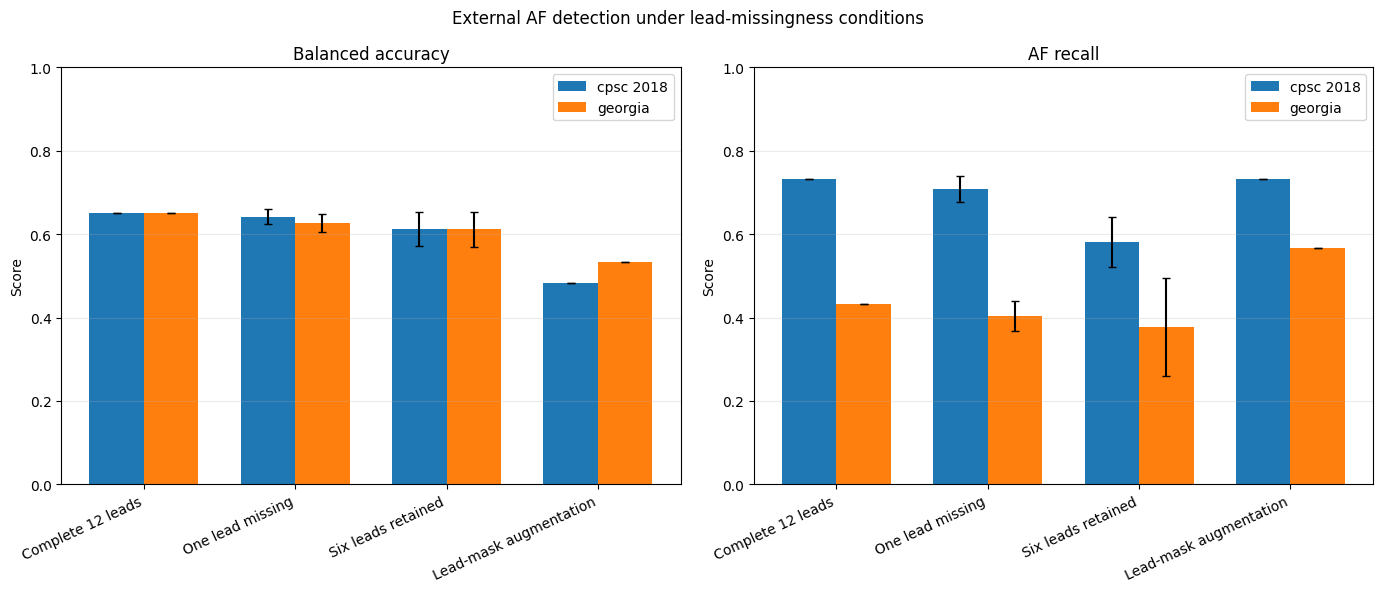

Backup verified: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/lead_observability_pilot/final_core_comparison.csv (762 bytes)
Backup verified: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/lead_observability_pilot/final_single_lead_bootstrap.csv (2,014 bytes)
Backup verified: /content/drive/MyDrive/mm-dg-healthcare-data/results_backup/lead_observability_pilot/final_core_comparison.png (198,019 bytes)
CSV content verified: final_core_comparison.csv
CSV content verified: final_single_lead_bootstrap.csv

FINAL COMPARISON
  dataset              condition  balanced_accuracy  bacc_sd  AF_recall  recall_sd
cpsc_2018      Complete 12 leads              0.650    0.000      0.733      0.000
cpsc_2018       One lead missing              0.642    0.018      0.708      0.032
cpsc_2018     Six leads retained              0.612    0.041      0.581      0.060
cpsc_2018 Lead-mask augmentation              0.483    0.000      0.733      0.000
  georgia      Complete 12 leads 

In [65]:
from pathlib import Path
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT = Path("/content/mm-dg-healthcare/experiments/results/lead_observability_pilot")
DRIVE = Path("/content/drive/MyDrive/mm-dg-healthcare-data/results_backup/lead_observability_pilot")

# Confirm Drive is mounted before writing anything
if not Path("/content/drive/MyDrive").exists():
    raise RuntimeError("Google Drive is not mounted. Run drive.mount('/content/drive') first.")

baseline = pd.read_csv(OUT / "af_cross_dataset_baseline_metrics.csv")
missing = pd.read_csv(OUT / "raw_signal_missing_lead_summary.csv")
aug = pd.read_csv(OUT / "lead_mask_training_comparison.csv")
bootstrap = pd.read_csv(OUT / "paired_bootstrap_single_lead_effects.csv")

# Validate the schemas
assert {"test_dataset", "balanced_accuracy", "recall_AF"}.issubset(baseline.columns)
assert {"dataset", "condition", "metric", "mean", "std"}.issubset(missing.columns)
assert {"test_dataset", "model", "balanced_accuracy", "AF_recall"}.issubset(aug.columns)

rows = []

# Complete-lead baseline
for _, r in baseline.iterrows():
    rows.append({
        "dataset": r["test_dataset"],
        "condition": "Complete 12 leads",
        "balanced_accuracy": r["balanced_accuracy"],
        "bacc_sd": 0.0,
        "AF_recall": r["recall_AF"],
        "recall_sd": 0.0,
    })

# Missing-lead summaries
for dataset in ["cpsc_2018", "georgia"]:
    for condition, label in [
        ("one_lead_missing", "One lead missing"),
        ("six_leads_retained", "Six leads retained"),
    ]:
        block = missing[
            (missing["dataset"] == dataset) &
            (missing["condition"] == condition)
        ]

        bacc = block[block["metric"] == "balanced_accuracy"]
        recall = block[block["metric"].isin(["AF_recall", "af_recall", "recall_AF"])]

        if bacc.empty or recall.empty:
            raise ValueError(
                f"Missing metric for {dataset}/{condition}. "
                f"Conditions found: {missing['condition'].unique().tolist()}; "
                f"metrics found: {missing['metric'].unique().tolist()}"
            )

        rows.append({
            "dataset": dataset,
            "condition": label,
            "balanced_accuracy": float(bacc.iloc[0]["mean"]),
            "bacc_sd": float(bacc.iloc[0]["std"]),
            "AF_recall": float(recall.iloc[0]["mean"]),
            "recall_sd": float(recall.iloc[0]["std"]),
        })

# Lead-mask augmentation results
for _, r in aug[aug["model"] == "lead_mask_augmentation"].iterrows():
    rows.append({
        "dataset": r["test_dataset"],
        "condition": "Lead-mask augmentation",
        "balanced_accuracy": r["balanced_accuracy"],
        "bacc_sd": 0.0,
        "AF_recall": r["AF_recall"],
        "recall_sd": 0.0,
    })

comparison = pd.DataFrame(rows)

order = [
    "Complete 12 leads",
    "One lead missing",
    "Six leads retained",
    "Lead-mask augmentation",
]
comparison["condition"] = pd.Categorical(
    comparison["condition"], categories=order, ordered=True
)
comparison = comparison.sort_values(["dataset", "condition"]).reset_index(drop=True)
comparison["condition"] = comparison["condition"].astype(str)

# Save consolidated tables
comparison_path = OUT / "final_core_comparison.csv"
bootstrap_path_out = OUT / "final_single_lead_bootstrap.csv"

comparison.to_csv(comparison_path, index=False)
bootstrap.to_csv(bootstrap_path_out, index=False)

# Plot comparison: balanced accuracy and AF recall
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
x = np.arange(len(order))
width = 0.36

for ax, metric, sd_metric, title in [
    (axes[0], "balanced_accuracy", "bacc_sd", "Balanced accuracy"),
    (axes[1], "AF_recall", "recall_sd", "AF recall"),
]:
    for i, dataset in enumerate(["cpsc_2018", "georgia"]):
        d = comparison[comparison["dataset"] == dataset].set_index("condition")
        means = [d.loc[c, metric] if c in d.index else np.nan for c in order]
        errors = [d.loc[c, sd_metric] if c in d.index else 0 for c in order]

        ax.bar(
            x + (i - 0.5) * width,
            means,
            width,
            yerr=errors,
            capsize=3,
            label=dataset.replace("_", " "),
        )

    ax.set_title(title)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=25, ha="right")
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

fig.suptitle("External AF detection under lead-missingness conditions")
fig.tight_layout()

figure_path = OUT / "final_core_comparison.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# Back up all outputs to Drive
DRIVE.mkdir(parents=True, exist_ok=True)

for src in [comparison_path, bootstrap_path_out, figure_path]:
    dst = DRIVE / src.name
    shutil.copy2(src, dst)
    assert dst.exists() and dst.stat().st_size == src.stat().st_size
    print(f"Backup verified: {dst} ({dst.stat().st_size:,} bytes)")

# Verify copied CSV contents
for name in ["final_core_comparison.csv", "final_single_lead_bootstrap.csv"]:
    pd.testing.assert_frame_equal(
        pd.read_csv(OUT / name),
        pd.read_csv(DRIVE / name),
        check_dtype=False,
    )
    print(f"CSV content verified: {name}")

print("\nFINAL COMPARISON")
print(comparison.round(3).to_string(index=False))

In [67]:

import os
from pathlib import Path
import subprocess

ROOT = Path("/content/mm-dg-healthcare")

print("=== 1. REPOSITORY ===")
if ROOT.exists():
    result = subprocess.run(
        ["git", "status", "--short", "--branch"],
        cwd=ROOT, capture_output=True, text=True
    )
    print(result.stdout or "(clean working tree)")
    print("\nProject files:")
    for p in sorted(ROOT.iterdir()):
        print(("DIR  " if p.is_dir() else "FILE "), p.name)
else:
    print("Repository not found at", ROOT)

print("\n=== 2. DATASET / RESULT DIRECTORIES ===")
for base in [Path("/content"), Path("/content/drive/MyDrive")]:
    print(f"\nLocation: {base}")
    if not base.exists():
        print("Not mounted / not found")
        continue

    # Inspect only shallow directory names; do not scan raw signal contents.
    try:
        for p in sorted(base.iterdir()):
            name = p.name.lower()
            if any(k in name for k in [
                "ptb", "chapman", "cpsc", "georgia",
                "ecg", "mm-dg", "result", "checkpoint",
                "model", "data"
            ]):
                print(("DIR  " if p.is_dir() else "FILE "), p)
    except PermissionError:
        print("Permission denied")

print("\n=== 3. PROJECT CONFIGS / NOTEBOOKS / RESULT FILES ===")
if ROOT.exists():
    extensions = {".yaml", ".yml", ".json", ".csv",
                  ".ipynb", ".pt", ".pth", ".log"}
    for p in sorted(ROOT.rglob("*")):
        if not p.is_file():
            continue
        if any(part.startswith(".") for part in p.parts):
            continue
        if p.suffix.lower() in extensions:
            try:
                size_mb = p.stat().st_size / (1024 * 1024)
                print(f"{p.relative_to(ROOT)}  ({size_mb:.2f} MB)")
            except OSError:
                pass


=== 1. REPOSITORY ===
## main...origin/main
?? data/pilot/


Project files:
DIR   .git
FILE  .gitignore
FILE  README.md
DIR   configs
DIR   data
DIR   experiments
DIR   notebooks
FILE  pytest.ini
FILE  requirements.txt
DIR   scripts
DIR   src
DIR   tests

=== 2. DATASET / RESULT DIRECTORIES ===

Location: /content
DIR   /content/mm-dg-healthcare
DIR   /content/sample_data

Location: /content/drive/MyDrive
DIR   /content/drive/MyDrive/mm-dg-healthcare-data

=== 3. PROJECT CONFIGS / NOTEBOOKS / RESULT FILES ===
configs/baseline_signal_only.yaml  (0.00 MB)
configs/fusion_full.yaml  (0.00 MB)
configs/fusion_metadata.yaml  (0.00 MB)
configs/fusion_robust.yaml  (0.00 MB)
data/raw/ptbxl/ptbxl_database.csv  (6.29 MB)
data/raw/ptbxl/scp_statements.csv  (0.01 MB)
experiments/results/lead_observability_pilot/af_cross_dataset_baseline_metrics.csv  (0.00 MB)
experiments/results/lead_observability_pilot/af_cross_dataset_confusion_matrices.json  (0.00 MB)
experiments/results/lead_observability_pilot/

In [68]:

import json
from pathlib import Path

root = Path("/content/mm-dg-healthcare")

# 1. Inspect the four-dataset compatibility audit
nb_path = root / "notebooks/07_dataset_compatibility_audit.ipynb"

if nb_path.exists():
    nb = json.loads(nb_path.read_text(encoding="utf-8"))
    for i, cell in enumerate(nb.get("cells", [])):
        source = "".join(cell.get("source", []))
        print(f"\n{'='*18} CELL {i} [{cell.get('cell_type')}] {'='*18}")
        print(source[:5000])

        for out in cell.get("outputs", []):
            text_out = out.get("text", [])
            if text_out:
                print("SAVED OUTPUT:")
                print("".join(text_out)[:2500])

            data = out.get("data", {})
            if "text/plain" in data:
                print("SAVED RESULT:")
                print("".join(data["text/plain"])[:2500])
else:
    print("Notebook 07 not found.")

# 2. Inspect the untracked pilot directory
pilot = root / "data/pilot"
print("\n=== DATA/PILOT CONTENTS ===")
if pilot.exists():
    for p in sorted(pilot.rglob("*")):
        if p.is_file():
            print(p.relative_to(root), f"{p.stat().st_size:,} bytes")

# 3. Check dataset directories and the saved configs
print("\n=== DATA DIRECTORIES ===")
for p in sorted((root / "data").rglob("*")):
    if p.is_dir() and len(p.relative_to(root / "data").parts) <= 3:
        print(p.relative_to(root))

print("\n=== EXPERIMENT CONFIGURATIONS ===")
for name in [
    "baseline_signal_only.yaml",
    "fusion_full.yaml",
    "fusion_metadata.yaml",
    "fusion_robust.yaml",
]:
    p = root / "configs" / name
    print(f"\n--- {name} ---")
    if p.exists():
        print(p.read_text(encoding="utf-8"))



================== CELL 0 [code] ==================
from google.colab import drive
drive.mount("/content/drive")

import os
import subprocess

REPO_URL = "https://github.com/Sakina152/mm-dg-healthcare.git"
REPO_DIR = "/content/mm-dg-healthcare"

if not os.path.isdir(os.path.join(REPO_DIR, ".git")):
    subprocess.run(
        ["git", "clone", REPO_URL, REPO_DIR],
        check=True
    )

os.chdir(REPO_DIR)
print("Working directory:", os.getcwd())
!git log -1 --oneline
SAVED OUTPUT:
Mounted at /content/drive
Working directory: /content/mm-dg-healthcare
08b333f (HEAD -> main, origin/main, origin/HEAD) Add multi-dataset compatibility audit


================== CELL 1 [code] ==================
from pathlib import Path

drive_backup = Path("/content/drive/MyDrive/mm-dg-healthcare-data")
archive = drive_backup / "ptbxl.tar"

print("Drive backup folder exists:", drive_backup.exists())
print("PTB-XL archive exists:", archive.exists())

if archive.exists():
    print(f"Archive size: {archive.